In [5]:
import pandas as pd
from pathlib import Path

file_path = Path(
    r"C:\Users\incog\Desktop\Portfolio_Project_Agriculture\data\processed\ble_supply_balance_final_1991-2025.xlsx"
)

df = pd.read_excel(file_path, engine="openpyxl")

display(df.head())

,Wirtschaftsjahr,Bilanz_Produkt,Ausfuhr,Einfuhr,Inlandsverwendung,Inlandsverwendung_insgesamt,Selbstversorgungsgrad_in_%,Verwendbare_Erzeugung,Inlandsverwendung_standardisiert,Importquote_in_%,...,Nahrungsverbrauch_in_Produktgewicht/_in_Mehlwert.1,Nahrungsverbrauch_in_kg_je_Kopf.1,Saatgut.1,Verluste.1,Nettohandelsbilanz,Inlandsverwendung_geprueft,Inlandsverwendung_Vorjahr,Inlandsverwendung_Veraenderung_%,Verwendbare_Erzeugung_Vorjahr,Verwendbare_Erzeugung_Veraenderung_%
0,1991/92,Gerste,3537.0,1233.0,NaN,10637.0,136.26022,14494.0,10637.0,11.591614,...,NaN,NaN,388.0,351.0,2304.0,10637.0,NaN,NaN,NaN,NaN
1,1991/92,Kartoffeln,1002.0,1757.0,10787.0,NaN,90.00000,9737.0,10787.0,16.288125,...,NaN,74.0,818.0,260.0,-755.0,10787.0,NaN,NaN,NaN,NaN
2,1991/92,Weichweizen,4941.0,1440.0,NaN,11639.0,142.03110,16531.0,11639.0,12.372197,...,NaN,NaN,473.0,402.0,3501.0,11639.0,NaN,NaN,NaN,NaN
3,1992/93,Gerste,2725.0,1035.0,NaN,10502.0,116.13026,12196.0,10502.0,9.855266,...,NaN,NaN,367.0,306.0,1690.0,10502.0,10637.0,-1.269155,14494.0,-15.854836
4,1992/93,Kartoffeln,1122.0,1458.0,10644.0,NaN,97.00000,10358.0,10644.0,13.697858,...,NaN,73.3,731.0,235.0,-336.0,10644.0,10787.0,-1.325670,9737.0,6.377734


In [6]:
# Tatsächliche Anzahl der Spalten
print("Anzahl Spalten:", len(df.columns))

# Spalten mit doppelten Namen
print("Doppelte Spaltennamen:")
print(df.columns[df.columns.duplicated()].tolist())

# Spalten mit dem Suffix .1
print("\nSpalten mit .1:")
print([col for col in df.columns if col.endswith(".1")])

# Datentypen und Anzahl der Nicht-Null-Werte
display(df.info())

Anzahl Spalten: 47
Doppelte Spaltennamen:
[]

Spalten mit .1:
['Futter.1', 'Industrielle_Verwertung.1', 'Industrielle_Verwertung_für_Energie.1', 'Nahrungsverbrauch.1', 'Nahrungsverbrauch_Ausbeute_in_%.1', 'Nahrungsverbrauch_Kartoffelerzeugnisse.1', 'Nahrungsverbrauch_in_Getreidewert.1', 'Nahrungsverbrauch_in_Getreidewert_in_kg_je_Kopf.1', 'Nahrungsverbrauch_in_Produktgewicht.1', 'Nahrungsverbrauch_in_Produktgewicht_in_kg_je_Kopf.1', 'Nahrungsverbrauch_in_Produktgewicht_in_kg_je_Kopf/_dgl._kg_je_Kopf.1', 'Nahrungsverbrauch_in_Produktgewicht/_in_Mehlwert.1', 'Nahrungsverbrauch_in_kg_je_Kopf.1', 'Saatgut.1', 'Verluste.1']
<class 'pandas.DataFrame'>
RangeIndex: 102 entries, 0 to 101
Data columns (total 47 columns):
 #   Column                                                                Non-Null Count  Dtype  
---  ------                                                                --------------  -----  
 0   Wirtschaftsjahr                                                       102 no

None

In [7]:

# Filter the dataset for soft wheat
df_weizen = df[
    df["Bilanz_Produkt"] == "Weichweizen"
].copy()

# Calculate deviations using standardized domestic utilization
results = calculate_deviations(
    df=df_weizen,
    crisis_year="2018/19",
    pre_years=3,
    post_years=5,
    value_col="Inlandsverwendung_standardisiert",
    crisis_length=2,
)

# Display only the selected indicator and its calculated deviations
display(
    results[
        [
            "Wirtschaftsjahr",
            "Inlandsverwendung_standardisiert",
            "Phase",
            "reference_level",
            "abs_deviation_level",
            "rel_deviation_level_pct",
            "trend_predicted",
            "abs_deviation_trend",
            "rel_deviation_trend_pct",
        ]
    ]
)


NameError: name 'calculate_deviations' is not defined

### Methodology: Calculation of Deviations from Pre-Crisis Reference Levels and Trends

The analysis evaluates changes in standardized domestic utilization relative to two pre-crisis benchmarks: the average pre-crisis level and the linear pre-crisis trend. The reference period consists of the three agricultural years preceding the crisis, while the crisis phase covers two agricultural years, starting in 2018/19. The subsequent five agricultural years are classified as the post-crisis period.

The average pre-crisis level is calculated as the arithmetic mean of the indicator values observed during the reference period. In addition, a linear trend is estimated using ordinary least squares to determine the expected development of domestic utilization if the pre-crisis trend had continued. Both benchmarks are used to calculate absolute and relative deviations between observed and expected values.

Absolute deviations are calculated as the difference between the observed value and the corresponding reference value. Relative deviations express this difference as a percentage of the absolute reference value. If the reference value is zero, the relative deviation is recorded as undefined (`NaN`).

To improve data reliability, the calculation includes validation procedures to identify duplicate observations and missing pre-crisis years. Missing observations during the crisis and post-crisis periods generate warnings, and only available observations are included in the results.

The resulting deviations provide a descriptive assessment of changes in standardized domestic utilization during and after the crisis. However, they should not be interpreted as causal estimates of the crisis effect, since other economic, political, environmental, and structural factors may also influence domestic utilization. Furthermore, the estimated linear trend is based on a relatively short pre-crisis period and should therefore be interpreted with caution.

In [8]:

import warnings
import numpy as np
import pandas as pd


def calculate_deviations(
    df,
    crisis_year,
    pre_years=3,
    post_years=5,
    value_col="Inlandsverwendung_standardisiert",
    crisis_length=2,
):
    """
    Calculate deviations from the pre-crisis reference level
    and the linear pre-crisis trend.

    Parameters:
        df: DataFrame containing the product data.
        crisis_year: Starting agricultural year, e.g. "2018/19".
        pre_years: Number of pre-crisis years used as reference.
        post_years: Number of post-crisis years to analyze.
        value_col: Column containing the indicator to analyze.
        crisis_length: Number of agricultural years in the crisis phase.

    Returns:
        DataFrame with observed values, reference levels,
        trend predictions, and absolute and relative deviations.
    """

    # Step 1: Validate parameters and required columns
    if pre_years < 2:
        raise ValueError("pre_years must be at least 2.")

    if crisis_length < 1 or post_years < 0:
        raise ValueError(
            "crisis_length must be >= 1 and post_years must be >= 0."
        )

    required_cols = ["Wirtschaftsjahr", value_col]
    missing_cols = [
        col for col in required_cols if col not in df.columns
    ]

    if missing_cols:
        raise ValueError(f"Missing required columns: {missing_cols}")

    # Step 2: Create a copy and extract the starting year
    # of each agricultural year for chronological analysis
    data = df.copy()

    data["year_start"] = pd.to_numeric(
        data["Wirtschaftsjahr"].astype(str).str[:4],
        errors="coerce",
    )

    # Step 3: Convert the selected indicator to numeric values
    # and remove rows with missing or invalid observations
    data[value_col] = pd.to_numeric(
        data[value_col],
        errors="coerce",
    )

    data = data.dropna(
        subset=["year_start", value_col]
    ).copy()

    data["year_start"] = data["year_start"].astype(int)

    # Step 4: Sort observations chronologically
    data = data.sort_values("year_start")

    # Step 5: Define the pre-crisis, crisis, and post-crisis periods
    try:
        crisis_start = int(str(crisis_year)[:4])
    except (ValueError, TypeError):
        raise ValueError(
            "crisis_year must begin with a valid four-digit year."
        )

    pre_start = crisis_start - pre_years
    pre_end = crisis_start - 1

    crisis_end = crisis_start + crisis_length - 1
    post_end = crisis_end + post_years

    # Step 6: Select observations within the complete analysis period
    analysis_data = data[
        data["year_start"].between(pre_start, post_end)
    ].copy()

    # Step 7: Check for duplicate observations in the analysis period
    duplicate_years = analysis_data.loc[
        analysis_data["year_start"].duplicated(keep=False),
        "year_start",
    ].unique()

    if len(duplicate_years) > 0:
        raise ValueError(
            "Multiple observations found for years: "
            f"{sorted(duplicate_years.tolist())}. "
            "Filter the DataFrame by product before analysis."
        )

    # Step 8: Verify that all expected pre-crisis years are available
    pre_data = analysis_data[
        analysis_data["year_start"].between(pre_start, pre_end)
    ].copy()

    expected_pre_years = set(
        range(pre_start, crisis_start)
    )

    available_pre_years = set(
        pre_data["year_start"]
    )

    missing_pre_years = sorted(
        expected_pre_years - available_pre_years
    )

    if missing_pre_years:
        raise ValueError(
            "Missing pre-crisis years: "
            f"{missing_pre_years}. "
            "The reference period is incomplete."
        )

    if len(pre_data) < 2:
        raise ValueError(
            "At least two valid pre-crisis observations "
            "are required to estimate a linear trend."
        )

    # Step 9: Warn about missing crisis and post-crisis years
    expected_analysis_years = set(
        range(pre_start, post_end + 1)
    )

    available_analysis_years = set(
        analysis_data["year_start"]
    )

    missing_analysis_years = sorted(
        expected_analysis_years - available_analysis_years
    )

    missing_crisis_post_years = [
        year for year in missing_analysis_years
        if year >= crisis_start
    ]

    if missing_crisis_post_years:
        warnings.warn(
            "Missing crisis/post-crisis years: "
            f"{missing_crisis_post_years}. "
            "Results contain only available observations.",
            UserWarning,
        )

    # Step 10: Calculate the average pre-crisis reference level
    reference_level = pre_data[value_col].mean()

    # Step 11: Estimate the linear pre-crisis trend
    # Center the time variable at the crisis start year
    x_pre = pre_data["year_start"] - crisis_start

    reference_trend = np.polyfit(
        x_pre,
        pre_data[value_col],
        deg=1,
    )

    # Step 12: Assign each observation to its corresponding phase
    analysis_data["Phase"] = np.select(
        [
            analysis_data["year_start"].between(
                pre_start, pre_end
            ),
            analysis_data["year_start"].between(
                crisis_start, crisis_end
            ),
            analysis_data["year_start"].between(
                crisis_end + 1, post_end
            ),
        ],
        ["Pre", "Crisis", "Post"],
        default="Outside",
    )

    # Step 13: Keep only observations within the analysis period
    results = analysis_data[
        analysis_data["Phase"] != "Outside"
    ].copy()

    # Step 14: Calculate absolute and relative deviations
    # from the average pre-crisis reference level
    results["reference_level"] = reference_level

    results["abs_deviation_level"] = (
        results[value_col] - reference_level
    )

    results["rel_deviation_level_pct"] = np.where(
        reference_level != 0,
        results["abs_deviation_level"]
        / abs(reference_level) * 100,
        np.nan,
    )

    # Step 15: Predict expected values based on the pre-crisis trend
    x_results = results["year_start"] - crisis_start

    results["trend_predicted"] = np.polyval(
        reference_trend,
        x_results,
    )

    # Step 16: Calculate deviations from the predicted trend
    results["abs_deviation_trend"] = (
        results[value_col] - results["trend_predicted"]
    )

    results["rel_deviation_trend_pct"] = np.where(
        results["trend_predicted"] != 0,
        results["abs_deviation_trend"]
        / abs(results["trend_predicted"]) * 100,
        np.nan,
    )

    # Step 17: Return results in chronological order
    return (
        results.drop(columns=["year_start"])
        .sort_values("Wirtschaftsjahr")
        .reset_index(drop=True)
    )


In [9]:

# Filter the dataset for soft wheat
df_weizen = df[
    df["Bilanz_Produkt"] == "Weichweizen"
].copy()

# Calculate deviations using standardized domestic utilization
results = calculate_deviations(
    df=df_weizen,
    crisis_year="2018/19",
    pre_years=3,
    post_years=5,
    value_col="Inlandsverwendung_standardisiert",
    crisis_length=2,
)

# Display only the selected indicator and its calculated deviations
display(
    results[
        [
            "Wirtschaftsjahr",
            "Inlandsverwendung_standardisiert",
            "Phase",
            "reference_level",
            "abs_deviation_level",
            "rel_deviation_level_pct",
            "trend_predicted",
            "abs_deviation_trend",
            "rel_deviation_trend_pct",
        ]
    ]
)


,Wirtschaftsjahr,Inlandsverwendung_standardisiert,Phase,reference_level,abs_deviation_level,rel_deviation_level_pct,trend_predicted,abs_deviation_trend,rel_deviation_trend_pct
0,2015/16,18901.20448,Pre,19310.67809,-409.47361,-2.120452,18881.20929,19.99519,0.105900
1,2016/17,19270.68771,Pre,19310.67809,-39.99038,-0.207089,19310.67809,-39.99038,-0.207089
2,2017/18,19760.14208,Pre,19310.67809,449.46399,2.327541,19740.14689,19.99519,0.101292
3,2018/19,17649.09647,Crisis,19310.67809,-1661.58162,-8.604471,20169.61569,-2520.51922,-12.496615
4,2019/20,17329.24806,Crisis,19310.67809,-1981.43003,-10.260800,20599.08449,-3269.83643,-15.873698
5,2020/21,17592.74989,Post,19310.67809,-1717.92820,-8.896260,21028.55329,-3435.80340,-16.338753
6,2021/22,16999.74958,Post,19310.67809,-2310.92851,-11.967102,21458.02209,-4458.27251,-20.776717
7,2022/23,17059.06809,Post,19310.67809,-2251.61000,-11.659922,21887.49089,-4828.42280,-22.060193
8,2023/24,17980.67474,Post,19310.67809,-1330.00335,-6.887398,22316.95969,-4336.28495,-19.430447
9,2024/25,16889.56155,Post,19310.67809,-2421.11654,-12.537709,22746.42849,-5856.86694,-25.748512


In [10]:
# Ergebnisse für alle Produkte berechnen
alle_results = []

for produkt, df_produkt in df.groupby("Bilanz_Produkt"):
    try:
        ergebnisse = calculate_deviations(
            df=df_produkt,
            crisis_year="2018/19",
            pre_years=3,
            post_years=5,
            value_col="Inlandsverwendung_standardisiert",
            crisis_length=2,
        )

        ergebnisse["Bilanz_Produkt"] = produkt
        alle_results.append(ergebnisse)

    except ValueError as e:
        print(f"Produkt '{produkt}' übersprungen: {e}")

# Alle Ergebnisse zusammenführen
if alle_results:
    results_alle_produkte = pd.concat(
        alle_results,
        ignore_index=True
    )
    print(f"Ergebnisse für {results_alle_produkte['Bilanz_Produkt'].nunique()} Produkte berechnet.")
else:
    print("Für kein Produkt konnten Ergebnisse berechnet werden.")

Ergebnisse für 3 Produkte berechnet.


In [11]:
# Letztes verfügbares Wirtschaftsjahr je Produkt
vergleich_letztes_jahr = (
    results_alle_produkte
    .sort_values("Wirtschaftsjahr")
    .groupby("Bilanz_Produkt", as_index=False)
    .tail(1)
    [
        [
            "Bilanz_Produkt",
            "Wirtschaftsjahr",
            "rel_deviation_level_pct",
            "rel_deviation_trend_pct",
        ]
    ]
    .sort_values("rel_deviation_level_pct")
    .reset_index(drop=True)
)

display(vergleich_letztes_jahr)

,Bilanz_Produkt,Wirtschaftsjahr,rel_deviation_level_pct,rel_deviation_trend_pct
0,Weichweizen,2024/25,-12.537709,-25.748512
1,Gerste,2024/25,-9.128677,14.974152
2,Kartoffeln,2024/25,17.197222,-10.141515


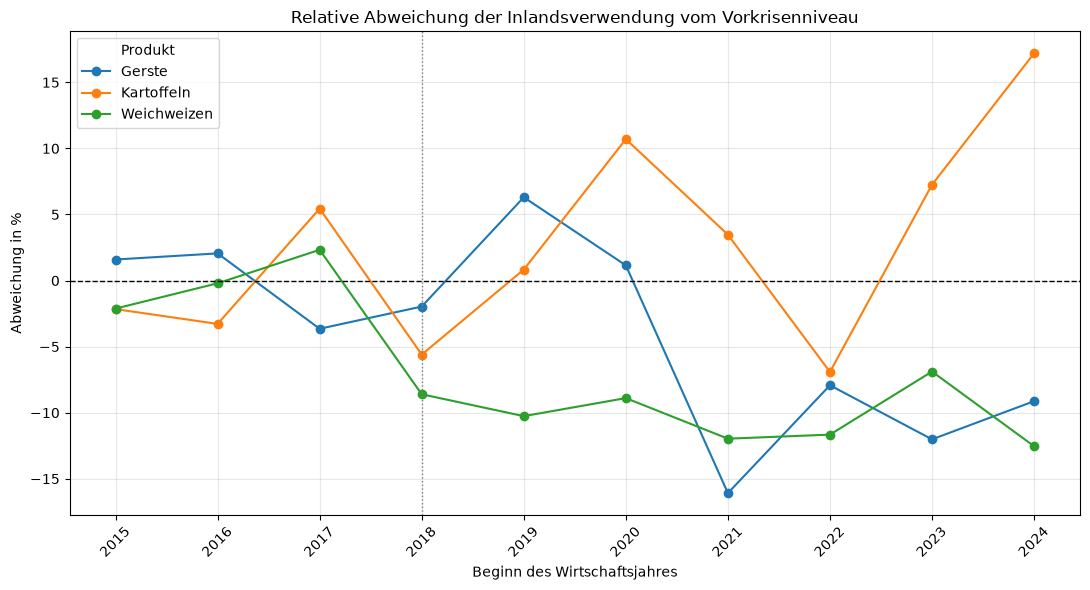

In [12]:
import matplotlib.pyplot as plt
import pandas as pd

# Daten für das Diagramm vorbereiten
plot_data = results_alle_produkte.copy()

# Beginn des Wirtschaftsjahres in eine Zahl umwandeln
plot_data["Jahr"] = pd.to_numeric(
    plot_data["Wirtschaftsjahr"].astype(str).str[:4],
    errors="coerce"
)

plot_data = plot_data.dropna(subset=["Jahr"])

# Relative Abweichung vom Vorkrisenniveau darstellen
plt.figure(figsize=(11, 6))

for produkt, daten in plot_data.groupby("Bilanz_Produkt"):
    daten = daten.sort_values("Jahr")
    plt.plot(
        daten["Jahr"],
        daten["rel_deviation_level_pct"],
        marker="o",
        label=produkt
    )

# Referenzlinie: keine Abweichung vom Vorkrisenniveau
plt.axhline(0, color="black", linewidth=1, linestyle="--")

# Krisenbeginn markieren
plt.axvline(2018, color="grey", linewidth=1, linestyle=":")

plt.title("Relative Abweichung der Inlandsverwendung vom Vorkrisenniveau")
plt.xlabel("Beginn des Wirtschaftsjahres")
plt.ylabel("Abweichung in %")
plt.xticks(sorted(plot_data["Jahr"].unique()), rotation=45)
plt.legend(title="Produkt")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

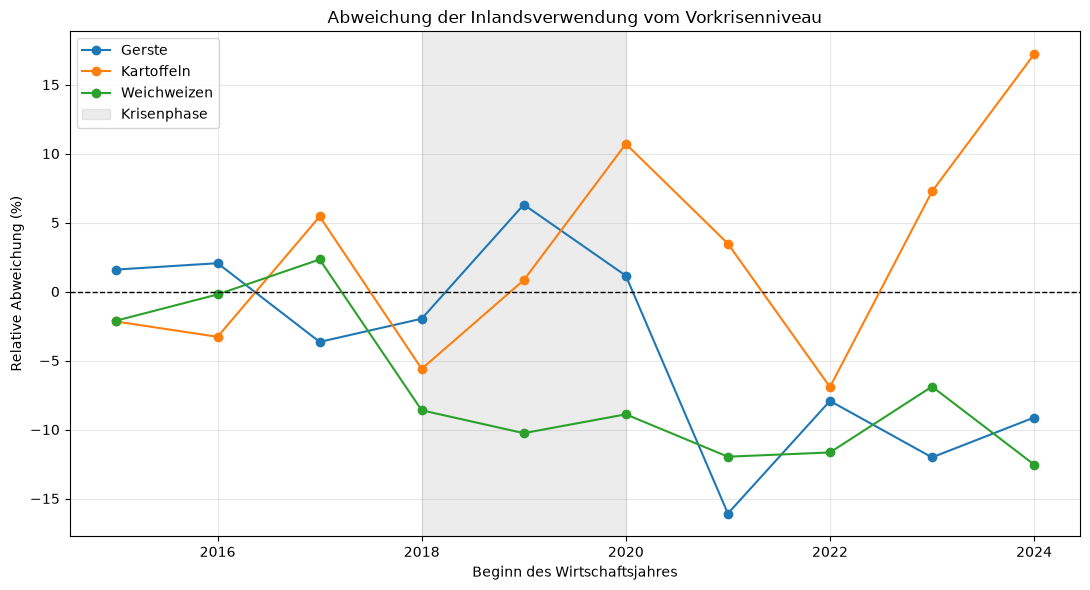

In [13]:
import matplotlib.pyplot as plt
import pandas as pd

plot_data = results_alle_produkte.copy()

plot_data["Jahr"] = pd.to_numeric(
    plot_data["Wirtschaftsjahr"].astype(str).str[:4],
    errors="coerce"
)

plot_data = plot_data.dropna(
    subset=["Jahr", "rel_deviation_level_pct"]
)

plt.figure(figsize=(11, 6))

for produkt, daten in plot_data.groupby("Bilanz_Produkt"):
    daten = daten.sort_values("Jahr")
    plt.plot(
        daten["Jahr"],
        daten["rel_deviation_level_pct"],
        marker="o",
        label=produkt
    )

plt.axhline(0, color="black", linestyle="--", linewidth=1)
plt.axvspan(2018, 2020, color="grey", alpha=0.15,
            label="Krisenphase")

plt.title("Abweichung der Inlandsverwendung vom Vorkrisenniveau")
plt.xlabel("Beginn des Wirtschaftsjahres")
plt.ylabel("Relative Abweichung (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [14]:

# Verfügbare Wirtschaftsjahre je Produkt prüfen
jahresuebersicht = (
    df.groupby("Bilanz_Produkt")["Wirtschaftsjahr"]
    .agg(
        erstes_jahr="min",
        letztes_jahr="max",
        anzahl_wirtschaftsjahre="nunique",
    )
    .reset_index()
)

display(jahresuebersicht)

# Alle Wirtschaftsjahre chronologisch anzeigen
jahre = (
    df[["Wirtschaftsjahr"]]
    .drop_duplicates()
    .assign(
        Jahr_Start=lambda x: pd.to_numeric(
            x["Wirtschaftsjahr"].astype(str).str[:4],
            errors="coerce",
        )
    )
    .sort_values("Jahr_Start")
    .drop(columns="Jahr_Start")
    .reset_index(drop=True)
)

display(jahre)


,Bilanz_Produkt,erstes_jahr,letztes_jahr,anzahl_wirtschaftsjahre
0,Gerste,1991/92,2024/25,34
1,Kartoffeln,1991/92,2024/25,34
2,Weichweizen,1991/92,2024/25,34


,Wirtschaftsjahr
0,1991/92
1,1992/93
2,1993/94
3,1994/95
4,1995/96
5,1996/97
6,1997/98
7,1998/99
8,1999/00
9,2000/01


In [15]:
# Relevante Spalten der BLE-Daten anzeigen
print("Verfügbare Spalten:")
for spalte in df.columns:
    print(spalte)

# Produkte und verfügbare Wirtschaftsjahre prüfen
print("\nProdukte:")
print(df["Bilanz_Produkt"].dropna().unique())

print("\nFrüheste und späteste Beobachtung:")
print(df["Wirtschaftsjahr"].min(), "bis", df["Wirtschaftsjahr"].max())

Verfügbare Spalten:
Wirtschaftsjahr
Bilanz_Produkt
Ausfuhr
Einfuhr
Inlandsverwendung
Inlandsverwendung_insgesamt
Selbstversorgungsgrad_in_%
Verwendbare_Erzeugung
Inlandsverwendung_standardisiert
Importquote_in_%
Exportquote_in_%
Futter
Industrielle_Verwertung
Industrielle_Verwertung_für_Energie
Nahrungsverbrauch
Nahrungsverbrauch_Ausbeute_in_%
Nahrungsverbrauch_Kartoffelerzeugnisse
Nahrungsverbrauch_in_Getreidewert
Nahrungsverbrauch_in_Getreidewert_in_kg_je_Kopf
Nahrungsverbrauch_in_Produktgewicht
Nahrungsverbrauch_in_Produktgewicht_in_kg_je_Kopf
Nahrungsverbrauch_in_Produktgewicht_in_kg_je_Kopf/_dgl._kg_je_Kopf
Nahrungsverbrauch_in_Produktgewicht/_in_Mehlwert
Nahrungsverbrauch_in_kg_je_Kopf
Saatgut
Verluste
Futter.1
Industrielle_Verwertung.1
Industrielle_Verwertung_für_Energie.1
Nahrungsverbrauch.1
Nahrungsverbrauch_Ausbeute_in_%.1
Nahrungsverbrauch_Kartoffelerzeugnisse.1
Nahrungsverbrauch_in_Getreidewert.1
Nahrungsverbrauch_in_Getreidewert_in_kg_je_Kopf.1
Nahrungsverbrauch_in_Produkt

In [26]:

# Produkte und Variablen für die Analyse
produkte = ["Weichweizen", "Gerste", "Kartoffeln"]

variablen = [
    "Verwendbare_Erzeugung",
    "Inlandsverwendung_standardisiert",
    "Einfuhr",
    "Ausfuhr",
    "Importquote_in_%",
    "Exportquote_in_%",
    "Selbstversorgungsgrad_in_%",
]

# Wirtschaftsjahre den drei Krisenepisoden zuordnen
krisen = {
    "Nahrungsmittelpreiskrise 2007–08": ["2007/08", "2008/09"],
    "Dürre und Hitze 2018–19": ["2018/19", "2019/20"],
    "Ukrainekrieg und Energiekrise": ["2021/22", "2022/23", "2023/24", "2024/25"],
}

# Datenabdeckung je Produkt und Krisenepisode prüfen
pruefung = []

for produkt in produkte:
    df_p = df[df["Bilanz_Produkt"] == produkt]

    for krise, jahre in krisen.items():
        df_k = df_p[df_p["Wirtschaftsjahr"].isin(jahre)]

        zeile = {
            "Produkt": produkt,
            "Krisenepisode": krise,
            "Vorhandene Wirtschaftsjahre": ", ".join(
                sorted(df_k["Wirtschaftsjahr"].dropna().unique())
            ),
        }

        for variable in variablen:
            if variable in df_k.columns:
                zeile[variable] = df_k[variable].notna().sum()
            else:
                zeile[variable] = "Spalte fehlt"

        pruefung.append(zeile)

display(pd.DataFrame(pruefung))


,Produkt,Krisenepisode,Vorhandene Wirtschaftsjahre,Verwendbare_Erzeugung,Inlandsverwendung_standardisiert,Einfuhr,Ausfuhr,Importquote_in_%,Exportquote_in_%,Selbstversorgungsgrad_in_%
0,Weichweizen,Nahrungsmittelpreiskrise 2007–08,"2007/08, 2008/09",2,2,2,2,2,2,2
1,Weichweizen,Dürre und Hitze 2018–19,"2018/19, 2019/20",2,2,2,2,2,2,2
2,Weichweizen,Ukrainekrieg und Energiekrise,"2021/22, 2022/23, 2023/24, 2024/25",4,4,4,4,4,4,4
3,Gerste,Nahrungsmittelpreiskrise 2007–08,"2007/08, 2008/09",2,2,2,2,2,2,2
4,Gerste,Dürre und Hitze 2018–19,"2018/19, 2019/20",2,2,2,2,2,2,2
5,Gerste,Ukrainekrieg und Energiekrise,"2021/22, 2022/23, 2023/24, 2024/25",4,4,4,4,4,4,4
6,Kartoffeln,Nahrungsmittelpreiskrise 2007–08,"2007/08, 2008/09",2,2,2,2,2,2,2
7,Kartoffeln,Dürre und Hitze 2018–19,"2018/19, 2019/20",2,2,2,2,2,2,2
8,Kartoffeln,Ukrainekrieg und Energiekrise,"2021/22, 2022/23, 2023/24, 2024/25",4,4,4,4,4,4,4


In [16]:

# Produkte und relevante BLE-Kennzahlen
produkte = ["Weichweizen", "Gerste", "Kartoffeln"]

variablen = [
    "Verwendbare_Erzeugung",
    "Inlandsverwendung_standardisiert",
    "Einfuhr",
    "Ausfuhr",
    "Importquote_in_%",
    "Exportquote_in_%",
    "Selbstversorgungsgrad_in_%",
]

# Krisenepisoden und Analysezeiträume
krisen = {
    "Nahrungsmittelpreiskrise 2007–08": {
        "crisis_year": "2007/08",
        "crisis_length": 2,
        "post_years": 5,
    },
    "Dürre und Hitze 2018–19": {
        "crisis_year": "2018/19",
        "crisis_length": 2,
        "post_years": 5,
    },
    "Ukrainekrieg und Energiekrise ab 2022": {
        "crisis_year": "2021/22",
        "crisis_length": 4,
        "post_years": 0,
    },
}

alle_ergebnisse = []

for produkt in produkte:
    df_produkt = df[df["Bilanz_Produkt"] == produkt].copy()

    for krise, parameter in krisen.items():
        for variable in variablen:
            try:
                ergebnis = calculate_deviations(
                    df=df_produkt,
                    crisis_year=parameter["crisis_year"],
                    pre_years=3,
                    post_years=parameter["post_years"],
                    value_col=variable,
                    crisis_length=parameter["crisis_length"],
                )

                # Metadaten ergänzen
                ergebnis["Bilanz_Produkt"] = produkt
                ergebnis["Krisenepisode"] = krise
                ergebnis["Kennzahl"] = variable

                # Ursprünglichen Messwert in eine gemeinsame Spalte schreiben
                ergebnis["Wert"] = ergebnis[variable]

                alle_ergebnisse.append(ergebnis)

            except ValueError as e:
                print(
                    f"Übersprungen: {produkt} | {krise} | "
                    f"{variable}: {e}"
                )

# Ergebnisse zusammenführen
if alle_ergebnisse:
    analyse_krisen = pd.concat(
        alle_ergebnisse,
        ignore_index=True
    )

    # Übersicht über die berechneten Ergebnisse
    display(
        analyse_krisen[
            [
                "Bilanz_Produkt",
                "Krisenepisode",
                "Kennzahl",
                "Wirtschaftsjahr",
                "Phase",
                "Wert",
                "reference_level",
                "abs_deviation_level",
                "rel_deviation_level_pct",
                "trend_predicted",
                "abs_deviation_trend",
                "rel_deviation_trend_pct",
            ]
        ].sort_values(
            ["Krisenepisode", "Bilanz_Produkt", "Kennzahl", "Wirtschaftsjahr"]
        )
    )
else:
    print("Es konnten keine Ergebnisse berechnet werden.")


,Bilanz_Produkt,Krisenepisode,Kennzahl,Wirtschaftsjahr,Phase,Wert,reference_level,abs_deviation_level,rel_deviation_level_pct,trend_predicted,abs_deviation_trend,rel_deviation_trend_pct
289,Gerste,Dürre und Hitze 2018–19,Ausfuhr,2015/16,Pre,3802.99063,3374.07629,428.91434,12.712052,3775.348835,27.641795,0.732165
290,Gerste,Dürre und Hitze 2018–19,Ausfuhr,2016/17,Pre,3318.79270,3374.07629,-55.28359,-1.638481,3374.076290,-55.283590,-1.638481
291,Gerste,Dürre und Hitze 2018–19,Ausfuhr,2017/18,Pre,3000.44554,3374.07629,-373.63075,-11.073571,2972.803745,27.641795,0.929822
292,Gerste,Dürre und Hitze 2018–19,Ausfuhr,2018/19,Crisis,2107.65955,3374.07629,-1266.41674,-37.533732,2571.531200,-463.871650,-18.038733
293,Gerste,Dürre und Hitze 2018–19,Ausfuhr,2019/20,Crisis,3071.61436,3374.07629,-302.46193,-8.964288,2170.258655,901.355705,41.532179
...,...,...,...,...,...,...,...,...,...,...,...,...
142,Weichweizen,Ukrainekrieg und Energiekrise ab 2022,Verwendbare_Erzeugung,2020/21,Pre,21989.10000,21674.13839,314.96161,1.453168,22605.980805,-616.880805,-2.728839
143,Weichweizen,Ukrainekrieg und Energiekrise ab 2022,Verwendbare_Erzeugung,2021/22,Crisis,21252.30000,21674.13839,-421.83839,-1.946275,23537.823220,-2285.523220,-9.710002
144,Weichweizen,Ukrainekrieg und Energiekrise ab 2022,Verwendbare_Erzeugung,2022/23,Crisis,22368.90000,21674.13839,694.76161,3.205487,24469.665635,-2100.765635,-8.585183
145,Weichweizen,Ukrainekrieg und Energiekrise ab 2022,Verwendbare_Erzeugung,2023/24,Crisis,21297.90000,21674.13839,-376.23839,-1.735886,25401.508050,-4103.608050,-16.154978


In [17]:

# Nur die Krisenjahre betrachten
krisen_summary = (
    analyse_krisen.loc[analyse_krisen["Phase"] == "Crisis"]
    .groupby(
        ["Krisenepisode", "Bilanz_Produkt", "Kennzahl"],
        as_index=False
    )
    .agg(
        Anzahl_Jahre=("Wert", "count"),
        Mittelwert=("Wert", "mean"),
        Referenzniveau=("reference_level", "mean"),
        Mittlere_Abweichung_absolut=(
            "abs_deviation_level", "mean"
        ),
        Mittlere_Abweichung_relativ_pct=(
            "rel_deviation_level_pct", "mean"
        ),
        Mittlere_Trendabweichung=(
            "abs_deviation_trend", "mean"
        ),
        Mittlere_Trendabweichung_pct=(
            "rel_deviation_trend_pct", "mean"
        ),
    )
)

display(
    krisen_summary.sort_values(
        ["Krisenepisode", "Bilanz_Produkt", "Kennzahl"]
    ).round(2)
)


,Krisenepisode,Bilanz_Produkt,Kennzahl,Anzahl_Jahre,Mittelwert,Referenzniveau,Mittlere_Abweichung_absolut,Mittlere_Abweichung_relativ_pct,Mittlere_Trendabweichung,Mittlere_Trendabweichung_pct
0,Dürre und Hitze 2018–19,Gerste,Ausfuhr,2,2589.64,3374.08,-784.44,-23.25,218.74,11.75
1,Dürre und Hitze 2018–19,Gerste,Einfuhr,2,1606.57,1637.05,-30.48,-1.86,142.35,9.65
2,Dürre und Hitze 2018–19,Gerste,Exportquote_in_%,2,24.25,30.42,-6.18,-20.31,0.14,1.35
3,Dürre und Hitze 2018–19,Gerste,Importquote_in_%,2,16.79,17.43,-0.63,-3.63,0.03,0.12
4,Dürre und Hitze 2018–19,Gerste,Inlandsverwendung_standardisiert,2,9602.22,9398.45,203.76,2.17,819.47,9.41
...,...,...,...,...,...,...,...,...,...,...
58,Ukrainekrieg und Energiekrise ab 2022,Weichweizen,Exportquote_in_%,4,45.19,42.75,2.44,5.71,-11.68,-20.39
59,Ukrainekrieg und Energiekrise ab 2022,Weichweizen,Importquote_in_%,4,34.57,27.27,7.30,26.77,2.86,8.96
60,Ukrainekrieg und Energiekrise ab 2022,Weichweizen,Inlandsverwendung_standardisiert,4,17232.26,17523.70,-291.43,-1.66,-192.83,-1.11
61,Ukrainekrieg und Energiekrise ab 2022,Weichweizen,Selbstversorgungsgrad_in_%,4,120.65,123.74,-3.09,-2.50,-22.27,-15.21


In [19]:

# Vergleich der mittleren relativen Abweichungen
vergleich = krisen_summary.pivot_table(
    index=["Bilanz_Produkt", "Kennzahl"],
    columns="Krisenepisode",
    values="Mittlere_Abweichung_relativ_pct"
)

# Krisenepisoden chronologisch sortieren
krisen_reihenfolge = [
    "Nahrungsmittelpreiskrise 2007–08",
    "Dürre und Hitze 2018–19",
    "Ukrainekrieg und Energiekrise ab 2022"
]

vergleich = vergleich.reindex(columns=krisen_reihenfolge)

display(vergleich.round(2))


Krisenepisode                                    Nahrungsmittelpreiskrise 2007–08  \
Bilanz_Produkt Kennzahl                                                             
Gerste         Ausfuhr                                                     -15.59   
               Einfuhr                                                      52.89   
               Exportquote_in_%                                             -8.14   
               Importquote_in_%                                             54.89   
               Inlandsverwendung_standardisiert                             -0.53   
               Selbstversorgungsgrad_in_%                                   -7.80   
               Verwendbare_Erzeugung                                        -8.08   
Kartoffeln     Ausfuhr                                                      14.16   
               Einfuhr                                                       5.21   
               Exportquote_in_%                                             11.77   
               Importquote_in_%                                             13.01   
               Inlandsverwendung_standardisiert                            -11.06   
               Selbstversorgungsgrad_in_%                                    9.81   
               Verwendbare_Erzeugung                                        -1.01   
Weichweizen    Ausfuhr                                                      25.32   
               Einfuhr                                                      89.85   
               Exportquote_in_%                                             24.96   
               Importquote_in_%                                             93.80   
               Inlandsverwendung_standardisiert                             -2.27   
               Selbstversorgungsgrad_in_%                                   -0.81   
               Verwendbare_Erzeugung                                        -1.81   

Krisenepisode                                    Dürre und Hitze 2018–19  \
Bilanz_Produkt Kennzahl                                                    
Gerste         Ausfuhr                                            -23.25   
               Einfuhr                                             -1.86   
               Exportquote_in_%                                   -20.31   
               Importquote_in_%                                    -3.63   
               Inlandsverwendung_standardisiert                     2.17   
               Selbstversorgungsgrad_in_%                          -6.64   
               Verwendbare_Erzeugung                               -4.37   
Kartoffeln     Ausfuhr                                             -5.21   
               Einfuhr                                             17.94   
               Exportquote_in_%                                     2.41   
               Importquote_in_%                                    21.08   
               Inlandsverwendung_standardisiert                    -2.39   
               Selbstversorgungsgrad_in_%                          -5.33   
               Verwendbare_Erzeugung                               -7.39   
Weichweizen    Ausfuhr                                            -20.12   
               Einfuhr                                            -16.15   
               Exportquote_in_%                                    -7.58   
               Importquote_in_%                                    -7.63   
               Inlandsverwendung_standardisiert                    -9.43   
               Selbstversorgungsgrad_in_%                          -5.12   
               Verwendbare_Erzeugung                              -14.05   

Krisenepisode                                    Ukrainekrieg und Energiekrise ab 2022  
Bilanz_Produkt Kennzahl                                                                 
Gerste         Ausfuhr                                                           39.66  
               Einfuhr      

In [21]:
vergleich = (
    krisen_summary
    .pivot(
        index=["Bilanz_Produkt", "Kennzahl"],
        columns="Krisenepisode",
        values="Mittlere_Abweichung_relativ_pct"
    )
    .reindex(columns=[
        "Nahrungsmittelpreiskrise 2007–08",
        "Dürre und Hitze 2018–19",
        "Ukrainekrieg und Energiekrise ab 2022"
    ])
    .rename_axis(columns=None)
    .round(2)
)

display(vergleich)

Nahrungsmittelpreiskrise 2007–08  \
Bilanz_Produkt Kennzahl                                                             
Gerste         Ausfuhr                                                     -15.59   
               Einfuhr                                                      52.89   
               Exportquote_in_%                                             -8.14   
               Importquote_in_%                                             54.89   
               Inlandsverwendung_standardisiert                             -0.53   
               Selbstversorgungsgrad_in_%                                   -7.80   
               Verwendbare_Erzeugung                                        -8.08   
Kartoffeln     Ausfuhr                                                      14.16   
               Einfuhr                                                       5.21   
               Exportquote_in_%                                             11.77   
               Importquote_in_%                                             13.01   
               Inlandsverwendung_standardisiert                            -11.06   
               Selbstversorgungsgrad_in_%                                    9.81   
               Verwendbare_Erzeugung                                        -1.01   
Weichweizen    Ausfuhr                                                      25.32   
               Einfuhr                                                      89.85   
               Exportquote_in_%                                             24.96   
               Importquote_in_%                                             93.80   
               Inlandsverwendung_standardisiert                             -2.27   
               Selbstversorgungsgrad_in_%                                   -0.81   
               Verwendbare_Erzeugung                                        -1.81   

                                                 Dürre und Hitze 2018–19  \
Bilanz_Produkt Kennzahl                                                    
Gerste         Ausfuhr                                            -23.25   
               Einfuhr                                             -1.86   
               Exportquote_in_%                                   -20.31   
               Importquote_in_%                                    -3.63   
               Inlandsverwendung_standardisiert                     2.17   
               Selbstversorgungsgrad_in_%                          -6.64   
               Verwendbare_Erzeugung                               -4.37   
Kartoffeln     Ausfuhr                                             -5.21   
               Einfuhr                                             17.94   
               Exportquote_in_%                                     2.41   
               Importquote_in_%                                    21.08   
               Inlandsverwendung_standardisiert                    -2.39   
               Selbstversorgungsgrad_in_%                          -5.33   
               Verwendbare_Erzeugung                               -7.39   
Weichweizen    Ausfuhr                                            -20.12   
               Einfuhr                                            -16.15   
               Exportquote_in_%                                    -7.58   
               Importquote_in_%                                    -7.63   
               Inlandsverwendung_standardisiert                    -9.43   
               Selbstversorgungsgrad_in_%                          -5.12   
               Verwendbare_Erzeugung                              -14.05   

                                                 Ukrainekrieg und Energiekrise ab 2022  
Bilanz_Produkt Kennzahl                                                                 
Gerste         Ausfuhr                                                           39.66  
               Einfuhr                                                       

In [23]:

vergleich = (
    krisen_summary
    .pivot(
        index=["Bilanz_Produkt", "Kennzahl"],
        columns="Krisenepisode",
        values="Mittlere_Abweichung_relativ_pct"
    )
    .reindex(columns=[
        "Nahrungsmittelpreiskrise 2007–08",
        "Dürre und Hitze 2018–19",
        "Ukrainekrieg und Energiekrise ab 2022"
    ])
    .reset_index()
)

vergleich.columns.name = None

# Sortierung nach Produkt und Kennzahl
vergleich = vergleich.sort_values(
    ["Bilanz_Produkt", "Kennzahl"]
).round(2)

display(vergleich)


,Bilanz_Produkt,Kennzahl,Nahrungsmittelpreiskrise 2007–08,Dürre und Hitze 2018–19,Ukrainekrieg und Energiekrise ab 2022
0,Gerste,Ausfuhr,-15.59,-23.25,39.66
1,Gerste,Einfuhr,52.89,-1.86,2.11
2,Gerste,Exportquote_in_%,-8.14,-20.31,38.35
3,Gerste,Importquote_in_%,54.89,-3.63,17.28
4,Gerste,Inlandsverwendung_standardisiert,-0.53,2.17,-12.88
5,Gerste,Selbstversorgungsgrad_in_%,-7.80,-6.64,16.73
6,Gerste,Verwendbare_Erzeugung,-8.08,-4.37,1.49
7,Kartoffeln,Ausfuhr,14.16,-5.21,16.88
8,Kartoffeln,Einfuhr,5.21,17.94,10.48
9,Kartoffeln,Exportquote_in_%,11.77,2.41,7.43


In [24]:

# 1. Fehlende Werte in wichtigen Ergebnisspalten prüfen
pruefspalten = [
    "Wert",
    "reference_level",
    "abs_deviation_level",
    "rel_deviation_level_pct",
    "trend_predicted",
    "abs_deviation_trend",
    "rel_deviation_trend_pct",
]

print("Fehlende Werte:")
display(analyse_krisen[pruefspalten].isna().sum())

# 2. Absolute Abweichung vom Referenzniveau prüfen
abweichung_level = (
    analyse_krisen["Wert"]
    - analyse_krisen["reference_level"]
)

print(
    "Maximale Rechendifferenz (Referenzniveau):",
    (abweichung_level
     - analyse_krisen["abs_deviation_level"])
    .abs()
    .max()
)

# 3. Absolute Trendabweichung prüfen
abweichung_trend = (
    analyse_krisen["Wert"]
    - analyse_krisen["trend_predicted"]
)

print(
    "Maximale Rechendifferenz (Trend):",
    (abweichung_trend
     - analyse_krisen["abs_deviation_trend"])
    .abs()
    .max()
)


Fehlende Werte:


Wert                       0
reference_level            0
abs_deviation_level        0
rel_deviation_level_pct    0
trend_predicted            0
abs_deviation_trend        0
rel_deviation_trend_pct    0
dtype: int64

Maximale Rechendifferenz (Referenzniveau): 0.0
Maximale Rechendifferenz (Trend): 0.0


# Verbesserte Berechnung

## Methodik der Krisen- und Abweichungsanalyse

### Berechnungsmethode

Zur Untersuchung ausgewählter Krisenepisoden werden die BLE-Kennzahlen für Weichweizen, Gerste und Kartoffeln mit dem jeweiligen durchschnittlichen Vorkrisenniveau sowie einem extrapolierten linearen Vorkrisentrend verglichen. Als Referenzzeitraum dienen die drei Wirtschaftsjahre vor Beginn der jeweiligen Krisenepisode. Berücksichtigt werden die in diesem Zeitraum verfügbaren gültigen Werte.

Das Referenzniveau entspricht dem arithmetischen Mittel der verfügbaren Beobachtungen im Vorkrisenzeitraum:

\[
\bar{x}_{\mathrm{vor}}=\frac{1}{n}\sum_{t=1}^{n}x_t
\]

Die absolute Abweichung ergibt sich aus der Differenz zwischen dem beobachteten Wert und dem Referenzniveau:

\[
\Delta x_t=x_t-\bar{x}_{\mathrm{vor}}
\]

Die relative Abweichung wird, sofern das Referenzniveau ungleich null ist, in Prozent berechnet:

\[
\Delta x_{t,\mathrm{rel}}=
\frac{x_t-\bar{x}_{\mathrm{vor}}}{\bar{x}_{\mathrm{vor}}}\cdot100
\]

Ergänzend wird anhand der verfügbaren Vorkrisenwerte ein linearer Trend geschätzt. Dieser wird auf die Krisen- und Folgejahre extrapoliert. Die absolute Trendabweichung entspricht der Differenz zwischen dem beobachteten Wert und dem geschätzten Trendwert. Die relative Trendabweichung setzt diese Differenz ins Verhältnis zum geschätzten Trendwert, sofern dieser ungleich null ist.

Die Krisenphasen werden für die Nahrungsmittelpreiskrise 2007–08, die Dürre- und Hitzeperiode 2018–19 sowie die Ukraine- und Energiekrise ab 2022 jeweils anhand der festgelegten Wirtschaftsjahre abgegrenzt. Für die beiden erstgenannten Episoden und die Ukraine- und Energiekrise wird in der vorliegenden Berechnung jeweils eine Dauer von zwei Wirtschaftsjahren angesetzt.

### Aussagekraft und Grenzen

Die Analyse zeigt, in welchem Umfang die beobachteten Kennzahlen vom durchschnittlichen Vorkrisenniveau und vom extrapolierten Vorkrisentrend abweichen. Dadurch lassen sich Veränderungen der verwendbaren Erzeugung, der Inlandsverwendung, des Außenhandels und des Selbstversorgungsgrads systematisch vergleichen, sofern die jeweiligen Kennzahlen in die Auswertung einbezogen werden.

Die Ergebnisse sind deskriptiv zu interpretieren und erlauben keinen eindeutigen Nachweis kausaler Krisenwirkungen. Beobachtete Veränderungen können auch durch andere Einflussfaktoren wie Witterung, Nachfrage, politische Maßnahmen oder internationale Marktbedingungen beeinflusst sein. Zudem basiert die Trendfortschreibung auf höchstens drei Vorkrisenjahren und kann daher empfindlich auf außergewöhnliche Ausgangswerte reagieren.

Für eine belastbare Interpretation ist zu prüfen, wie viele gültige Vorkrisenwerte den einzelnen Berechnungen zugrunde liegen. Die Berechnungsfunktion setzt mindestens zwei gültige Vorkrisenwerte voraus. Fehlen ausreichend Werte, wird die betreffende Berechnung nicht durchgeführt.

Der Referenzzeitraum der Ukraine- und Energiekrise umfasst bei einem Krisenbeginn im Wirtschaftsjahr 2022/23 die drei vorangehenden Wirtschaftsjahre 2019/20 bis 2021/22. Dieser Zeitraum ist angesichts außergewöhnlicher wirtschaftlicher und gesellschaftlicher Entwicklungen nicht ohne Weiteres als uneingeschränkt normaler Vergleichszeitraum zu betrachten.

Bei Quoten und Anteilswerten ist zwischen absoluten Abweichungen in Prozentpunkten und relativen Veränderungen in Prozent zu unterscheiden. Die Interpretation richtet sich daher nach der jeweiligen Kennzahl und ihrer Maßeinheit.

### Auswertung der Ergebnisse

Die Ergebnisse werden nach Krisenepisode, Produkt und Kennzahl verglichen. Abweichungen bei der verwendbaren Erzeugung geben Hinweise auf Veränderungen der ausgewiesenen Produktionsmenge. Veränderungen der Ein- und Ausfuhr sowie der Import- und Exportquoten zeigen mögliche Verschiebungen im Außenhandel. Der Selbstversorgungsgrad ergänzt die Analyse um die Relation zwischen heimischer Erzeugung und Inlandsverwendung.

Die Kennzahlen werden gemeinsam und produktspezifisch interpretiert, da einzelne Indikatoren allein kein vollständiges Bild der Versorgungslage liefern. Die beobachteten Muster werden als Hinweise auf mögliche Übertragungskanäle der Krisen verstanden, nicht als eindeutiger Nachweis ihrer Ursachen.

### Zusammenfassung und Vergleich der Krisenabweichungen

Für jede Kombination aus Krisenepisode, Produkt und Kennzahl werden die Beobachtungen der definierten Krisenjahre zusammengefasst. Dabei werden die Anzahl der verfügbaren Jahreswerte, der mittlere Kennzahlenwert, das Referenzniveau sowie die mittleren absoluten und relativen Abweichungen vom Vorkrisenniveau berechnet. Zusätzlich werden die absoluten und relativen Abweichungen vom extrapolierten Vorkrisentrend ermittelt.

Für den übergreifenden Vergleich der Krisenepisoden wird die mittlere relative Abweichung vom Vorkrisenniveau herangezogen. Dazu werden die Ergebnisse nach Produkt und Kennzahl angeordnet und die drei Krisenepisoden in separaten Spalten gegenübergestellt. Die Vergleichstabelle zeigt somit, um wie viel Prozent die Kennzahlenwerte während einer Krisenphase im Durchschnitt über oder unter dem jeweiligen durchschnittlichen Vorkrisenniveau liegen.

Die Trendabweichungen werden ergänzend berechnet, sind jedoch nicht Bestandteil dieser Vergleichstabelle. Sie können separat ausgewertet werden, um zu untersuchen, in welchem Umfang die beobachteten Werte vom anhand der Vorkrisenjahre geschätzten linearen Trend abweichen.

In [25]:

import numpy as np
import pandas as pd


def calculate_deviations(
    df,
    crisis_year,
    pre_years=3,
    post_years=5,
    value_col="Verwendbare_Erzeugung",
    crisis_length=2,
):
    required = ["Wirtschaftsjahr", "Bilanz_Produkt", value_col]
    missing = [c for c in required if c not in df.columns]

    if missing:
        raise ValueError(f"Fehlende Spalten: {missing}")

    data = df[required].copy()

    # Wirtschaftsjahr in Startjahr umwandeln, z. B. 2018/19 -> 2018
    data["Jahr"] = pd.to_numeric(
        data["Wirtschaftsjahr"].astype(str).str[:4],
        errors="coerce"
    )

    data[value_col] = pd.to_numeric(
        data[value_col], errors="coerce"
    )

    if data["Jahr"].isna().any():
        raise ValueError("Wirtschaftsjahre konnten nicht gelesen werden.")

    if data.duplicated(["Bilanz_Produkt", "Jahr"]).any():
        raise ValueError(
            "Mehrere Zeilen pro Produkt und Jahr vorhanden."
        )

    crisis_start = int(str(crisis_year)[:4])
    pre_start = crisis_start - pre_years
    pre_end = crisis_start - 1
    crisis_end = crisis_start + crisis_length - 1
    post_end = crisis_end + post_years

    data = data.sort_values("Jahr").copy()

    # Referenzzeitraum und Krisenphasen
    pre = data[
        data["Jahr"].between(pre_start, pre_end)
    ].dropna(subset=[value_col])

    if len(pre) < 2:
        raise ValueError(
            f"Zu wenige Vorkrisenwerte für {value_col}."
        )

    # Referenzniveau
    reference_level = pre[value_col].mean()

    # Linearen Trend ausschließlich im Vorkrisenzeitraum schätzen
    x_pre = pre["Jahr"].to_numpy(dtype=float)
    y_pre = pre[value_col].to_numpy(dtype=float)

    slope, intercept = np.polyfit(x_pre, y_pre, 1)

    # Phasen zuordnen
    data["Phase"] = "Outside"
    data.loc[
        data["Jahr"].between(pre_start, pre_end), "Phase"
    ] = "Pre"
    data.loc[
        data["Jahr"].between(crisis_start, crisis_end), "Phase"
    ] = "Crisis"
    data.loc[
        data["Jahr"].between(crisis_end + 1, post_end), "Phase"
    ] = "Post"

    # Abweichungen berechnen
    data["reference_level"] = reference_level
    data["abs_deviation_level"] = (
        data[value_col] - reference_level
    )

    if reference_level != 0:
        data["rel_deviation_level_pct"] = (
            data["abs_deviation_level"] / reference_level * 100
        )
    else:
        data["rel_deviation_level_pct"] = np.nan

    data["trend_predicted"] = (
        intercept + slope * data["Jahr"]
    )

    data["abs_deviation_trend"] = (
        data[value_col] - data["trend_predicted"]
    )

    data["rel_deviation_trend_pct"] = np.where(
        data["trend_predicted"] != 0,
        data["abs_deviation_trend"]
        / data["trend_predicted"] * 100,
        np.nan
    )

    return data


In [27]:
krisen_summary = (
    analyse_krisen[
        analyse_krisen["Phase"] == "Crisis"
    ]
    .groupby(
        ["Krisenepisode", "Bilanz_Produkt", "Kennzahl"],
        as_index=False
    )
    .agg(
        Anzahl_Jahre=("Wert", "count"),
        Mittelwert=("Wert", "mean"),
        Referenzniveau=("reference_level", "mean"),
        Mittlere_Abweichung_absolut=(
            "abs_deviation_level", "mean"
        ),
        Mittlere_Abweichung_relativ_pct=(
            "rel_deviation_level_pct", "mean"
        ),
        Mittlere_Trendabweichung=(
            "abs_deviation_trend", "mean"
        ),
        Mittlere_Trendabweichung_pct=(
            "rel_deviation_trend_pct", "mean"
        ),
    )
)

vergleich = (
    krisen_summary
    .pivot(
        index=["Bilanz_Produkt", "Kennzahl"],
        columns="Krisenepisode",
        values="Mittlere_Abweichung_relativ_pct"
    )
    .reindex(columns=[
        "Nahrungsmittelpreiskrise 2007–08",
        "Dürre und Hitze 2018–19",
        "Ukrainekrieg und Energiekrise ab 2022"
    ])
    .reset_index()
)

vergleich.columns.name = None

# Sortierung nach Produkt und Kennzahl
vergleich = vergleich.sort_values(
    ["Bilanz_Produkt", "Kennzahl"]
).round(2)

display(vergleich)

,Bilanz_Produkt,Kennzahl,Nahrungsmittelpreiskrise 2007–08,Dürre und Hitze 2018–19,Ukrainekrieg und Energiekrise ab 2022
0,Gerste,Ausfuhr,-15.59,-23.25,39.66
1,Gerste,Einfuhr,52.89,-1.86,2.11
2,Gerste,Exportquote_in_%,-8.14,-20.31,38.35
3,Gerste,Importquote_in_%,54.89,-3.63,17.28
4,Gerste,Inlandsverwendung_standardisiert,-0.53,2.17,-12.88
5,Gerste,Selbstversorgungsgrad_in_%,-7.80,-6.64,16.73
6,Gerste,Verwendbare_Erzeugung,-8.08,-4.37,1.49
7,Kartoffeln,Ausfuhr,14.16,-5.21,16.88
8,Kartoffeln,Einfuhr,5.21,17.94,10.48
9,Kartoffeln,Exportquote_in_%,11.77,2.41,7.43


# Nahrungsverbrauch

In [30]:

# Kennzahlen zum Nahrungsverbrauch auswählen
nahrungsverbrauch_kennzahlen = [
    "Nahrungsverbrauch",
    "Nahrungsverbrauch_Ausbeute_in_%",
    "Nahrungsverbrauch_Kartoffelerzeugnisse",
    "Nahrungsverbrauch_in_Getreidewert",
    "Nahrungsverbrauch_in_Getreidewert_in_kg_je_Kopf",
    "Nahrungsverbrauch_in_Produktgewicht",
    "Nahrungsverbrauch_in_Produktgewicht_in_kg_je_Kopf",
    "Nahrungsverbrauch_in_Produktgewicht_in_kg_je_Kopf/_dgl._kg_je_Kopf",
    "Nahrungsverbrauch_in_Produktgewicht/_in_Mehlwert",
    "Nahrungsverbrauch_in_kg_je_Kopf",
]

# Krisenjahre und relevante Kennzahlen filtern
nahrungsverbrauch_krisen = analyse_krisen[
    (analyse_krisen["Phase"] == "Crisis")
    & (
        analyse_krisen["Kennzahl"].isin(
            nahrungsverbrauch_kennzahlen
        )
    )
].copy()

# Zusammenfassung der Krisenkennzahlen
nahrungsverbrauch_summary = (
    nahrungsverbrauch_krisen
    .groupby(
        ["Krisenepisode", "Bilanz_Produkt", "Kennzahl"],
        as_index=False
    )
    .agg(
        Anzahl_Jahre=("Wert", "count"),
        Mittelwert=("Wert", "mean"),
        Referenzniveau=("reference_level", "mean"),
        Mittlere_Abweichung_absolut=(
            "abs_deviation_level", "mean"
        ),
        Mittlere_Abweichung_relativ_pct=(
            "rel_deviation_level_pct", "mean"
        ),
        Mittlere_Trendabweichung=(
            "abs_deviation_trend", "mean"
        ),
        Mittlere_Trendabweichung_pct=(
            "rel_deviation_trend_pct", "mean"
        ),
    )
)

# Vergleich der mittleren relativen Abweichungen
vergleich_nahrungsverbrauch = (
    nahrungsverbrauch_summary
    .pivot(
        index=["Bilanz_Produkt", "Kennzahl"],
        columns="Krisenepisode",
        values="Mittlere_Abweichung_relativ_pct"
    )
    .reindex(columns=[
        "Nahrungsmittelpreiskrise 2007–08",
        "Dürre und Hitze 2018–19",
        "Ukrainekrieg und Energiekrise ab 2022"
    ])
    .reset_index()
)

vergleich_nahrungsverbrauch.columns.name = None

# Nach Produkt und Kennzahl sortieren
vergleich_nahrungsverbrauch = (
    vergleich_nahrungsverbrauch
    .sort_values(["Bilanz_Produkt", "Kennzahl"])
    .round(2)
    .reset_index(drop=True)
)

display(vergleich_nahrungsverbrauch)


,Bilanz_Produkt,Kennzahl,Nahrungsmittelpreiskrise 2007–08,Dürre und Hitze 2018–19,Ukrainekrieg und Energiekrise ab 2022


In [31]:
print(
    analyse_krisen.loc[
        analyse_krisen["Kennzahl"].str.contains(
            "Nahrungsverbrauch",
            case=False,
            na=False
        ),
        "Kennzahl"
    ].drop_duplicates().to_list()
)

[]


In [32]:
print(
    analyse_krisen.loc[
        analyse_krisen["Phase"] == "Crisis",
        "Kennzahl"
    ].value_counts().to_string()
)

Kennzahl
Verwendbare_Erzeugung               24
Inlandsverwendung_standardisiert    24
Einfuhr                             24
Ausfuhr                             24
Importquote_in_%                    24
Exportquote_in_%                    24
Selbstversorgungsgrad_in_%          24


In [33]:
# Alle Nahrungsverbrauchskennzahlen automatisch auswählen
nahrungsverbrauch_krisen = analyse_krisen[
    (analyse_krisen["Phase"] == "Crisis")
    & (
        analyse_krisen["Kennzahl"].str.contains(
            "Nahrungsverbrauch",
            case=False,
            na=False
        )
    )
].copy()

print("Anzahl der gefundenen Zeilen:", len(nahrungsverbrauch_krisen))

print(
    nahrungsverbrauch_krisen[
        ["Bilanz_Produkt", "Kennzahl", "Wirtschaftsjahr"]
    ].head(10)
)

Anzahl der gefundenen Zeilen: 0
Empty DataFrame
Columns: [Bilanz_Produkt, Kennzahl, Wirtschaftsjahr]
Index: []


In [34]:
print("Spalten in df:")
print(df.columns.tolist())

Spalten in df:
['Wirtschaftsjahr', 'Bilanz_Produkt', 'Ausfuhr', 'Einfuhr', 'Inlandsverwendung', 'Inlandsverwendung_insgesamt', 'Selbstversorgungsgrad_in_%', 'Verwendbare_Erzeugung', 'Inlandsverwendung_standardisiert', 'Importquote_in_%', 'Exportquote_in_%', 'Futter', 'Industrielle_Verwertung', 'Industrielle_Verwertung_für_Energie', 'Nahrungsverbrauch', 'Nahrungsverbrauch_Ausbeute_in_%', 'Nahrungsverbrauch_Kartoffelerzeugnisse', 'Nahrungsverbrauch_in_Getreidewert', 'Nahrungsverbrauch_in_Getreidewert_in_kg_je_Kopf', 'Nahrungsverbrauch_in_Produktgewicht', 'Nahrungsverbrauch_in_Produktgewicht_in_kg_je_Kopf', 'Nahrungsverbrauch_in_Produktgewicht_in_kg_je_Kopf/_dgl._kg_je_Kopf', 'Nahrungsverbrauch_in_Produktgewicht/_in_Mehlwert', 'Nahrungsverbrauch_in_kg_je_Kopf', 'Saatgut', 'Verluste', 'Futter.1', 'Industrielle_Verwertung.1', 'Industrielle_Verwertung_für_Energie.1', 'Nahrungsverbrauch.1', 'Nahrungsverbrauch_Ausbeute_in_%.1', 'Nahrungsverbrauch_Kartoffelerzeugnisse.1', 'Nahrungsverbrauch_in_

In [43]:

import numpy as np
import pandas as pd

# ============================================================
# 1. FUNKTION ZUR BERECHNUNG DER KRISENABWEICHUNGEN
# ============================================================

def calculate_deviations(
    df,
    crisis_year,
    pre_years=3,
    post_years=5,
    value_col="Verwendbare_Erzeugung",
    crisis_length=2,
):
    required = ["Wirtschaftsjahr", "Bilanz_Produkt", value_col]
    missing = [c for c in required if c not in df.columns]

    if missing:
        raise ValueError(f"Fehlende Spalten: {missing}")

    data = df[required].copy()

    data["Jahr"] = pd.to_numeric(
        data["Wirtschaftsjahr"].astype(str).str[:4],
        errors="coerce"
    )

    data[value_col] = pd.to_numeric(
        data[value_col],
        errors="coerce"
    )

    if data["Jahr"].isna().any():
        raise ValueError("Wirtschaftsjahre konnten nicht gelesen werden.")

    if data.duplicated(["Bilanz_Produkt", "Jahr"]).any():
        raise ValueError("Mehrere Zeilen pro Produkt und Jahr vorhanden.")

    crisis_start = int(str(crisis_year)[:4])
    pre_start = crisis_start - pre_years
    pre_end = crisis_start - 1
    crisis_end = crisis_start + crisis_length - 1
    post_end = crisis_end + post_years

    data = data.sort_values("Jahr").copy()

    pre = data[
        data["Jahr"].between(pre_start, pre_end)
    ].dropna(subset=[value_col])

    if len(pre) < 2:
        raise ValueError(
            f"Zu wenige Vorkrisenwerte für {value_col}."
        )

    # Referenzniveau: Mittelwert der Vorkrisenjahre
    reference_level = pre[value_col].mean()

    # Linearer Trend vor der Krise
    x_pre = pre["Jahr"].to_numpy(dtype=float)
    y_pre = pre[value_col].to_numpy(dtype=float)

    slope, intercept = np.polyfit(x_pre, y_pre, 1)

    # Phasen zuordnen
    data["Phase"] = "Outside"

    data.loc[
        data["Jahr"].between(pre_start, pre_end), "Phase"
    ] = "Pre"

    data.loc[
        data["Jahr"].between(crisis_start, crisis_end), "Phase"
    ] = "Crisis"

    data.loc[
        data["Jahr"].between(crisis_end + 1, post_end), "Phase"
    ] = "Post"

    # Abweichung vom Referenzniveau
    data["reference_level"] = reference_level
    data["abs_deviation_level"] = (
        data[value_col] - reference_level
    )

    if reference_level != 0:
        data["rel_deviation_level_pct"] = (
            data["abs_deviation_level"] / reference_level * 100
        )
    else:
        data["rel_deviation_level_pct"] = np.nan

    # Abweichung vom linearen Vorkrisentrend
    data["trend_predicted"] = (
        intercept + slope * data["Jahr"]
    )

    data["abs_deviation_trend"] = (
        data[value_col] - data["trend_predicted"]
    )

    data["rel_deviation_trend_pct"] = np.where(
        data["trend_predicted"] != 0,
        data["abs_deviation_trend"]
        / data["trend_predicted"] * 100,
        np.nan
    )

    return data


# ============================================================
# 2. KRISENEPISODEN FESTLEGEN
# ============================================================

krisen = [
    {
        "name": "Nahrungsmittelpreiskrise 2007–08",
        "crisis_year": "2007/08",
        "crisis_length": 2,
    },
    {
        "name": "Dürre und Hitze 2018–19",
        "crisis_year": "2018/19",
        "crisis_length": 2,
    },
    {
        "name": "Ukrainekrieg und Energiekrise ab 2022",
        "crisis_year": "2022/23",
        "crisis_length": 2,
    },
]

# Produkte, die analysiert werden sollen
produkte = ["Gerste", "Kartoffeln", "Weichweizen"]


# ============================================================
# 3. NAHRUNGSVERBRAUCHSKENNZAHLEN AUSWÄHLEN
# ============================================================

# Spalten mit Suffix .1 vorerst ausschließen.
# Erst nach Prüfung der Originalüberschriften entscheiden,
# ob sie eigene fachliche Kennzahlen darstellen.

nahrungskennzahlen = [
    col for col in df.columns
    if "Nahrungsverbrauch" in col
    and not col.endswith(".1")
]

print("Berücksichtigte Kennzahlen:")
print(nahrungskennzahlen)


# ============================================================
# 4. KRISENABWEICHUNGEN BERECHNEN
# ============================================================

alle_ergebnisse = []
übersprungene_kombinationen = []

for produkt in produkte:

    df_produkt = df[
        df["Bilanz_Produkt"] == produkt
    ].copy()

    if df_produkt.empty:
        print(f"Warnung: Keine Daten für {produkt}")
        continue

    for kennzahl in nahrungskennzahlen:

        # Werte in numerisches Format umwandeln
        df_produkt[kennzahl] = pd.to_numeric(
            df_produkt[kennzahl],
            errors="coerce"
        )

        # Kennzahlen ohne jegliche Werte nicht berechnen
        if df_produkt[kennzahl].notna().sum() == 0:
            continue

        for krise in krisen:

            try:
                ergebnis = calculate_deviations(
                    df=df_produkt,
                    crisis_year=krise["crisis_year"],
                    pre_years=3,
                    post_years=5,
                    value_col=kennzahl,
                    crisis_length=krise["crisis_length"],
                )

            except ValueError as e:
                übersprungene_kombinationen.append({
                    "Produkt": produkt,
                    "Kennzahl": kennzahl,
                    "Krise": krise["name"],
                    "Grund": str(e),
                })
                continue

            # Einheitliche Wertespalte für alle Kennzahlen
            ergebnis["Wert"] = ergebnis[kennzahl]

            # Produkt, Kennzahl und Krise kennzeichnen
            ergebnis["Krisenepisode"] = krise["name"]
            ergebnis["Kennzahl"] = kennzahl

            # Nur die Krisenjahre behalten
            ergebnis = ergebnis[
                ergebnis["Phase"] == "Crisis"
            ].copy()

            alle_ergebnisse.append(ergebnis)


# ============================================================
# 5. ERGEBNISSE ZUSAMMENFÜHREN
# ============================================================

if not alle_ergebnisse:
    raise ValueError(
        "Es konnten keine Krisenergebnisse berechnet werden. "
        "Bitte prüfe die Daten und Vorkrisenwerte."
    )

analyse_nahrungsverbrauch = pd.concat(
    alle_ergebnisse,
    ignore_index=True
)


# ============================================================
# 6. MITTLERE ABWEICHUNGEN JE KRISE, PRODUKT UND KENNZAHL
# ============================================================

nahrungsverbrauch_summary = (
    analyse_nahrungsverbrauch
    .groupby(
        ["Krisenepisode", "Bilanz_Produkt", "Kennzahl"],
        as_index=False
    )
    .agg(
        Anzahl_Jahre=("Wert", "count"),
        Mittelwert=("Wert", "mean"),
        Referenzniveau=("reference_level", "mean"),
        Mittlere_Abweichung_absolut=(
            "abs_deviation_level", "mean"
        ),
        Mittlere_Abweichung_relativ_pct=(
            "rel_deviation_level_pct", "mean"
        ),
        Mittlere_Trendabweichung=(
            "abs_deviation_trend", "mean"
        ),
        Mittlere_Trendabweichung_pct=(
            "rel_deviation_trend_pct", "mean"
        ),
    )
)


# ============================================================
# 7. VERGLEICHSTABELLE ERSTELLEN
# ============================================================

krisen_reihenfolge = [
    "Nahrungsmittelpreiskrise 2007–08",
    "Dürre und Hitze 2018–19",
    "Ukrainekrieg und Energiekrise ab 2022",
]

vergleich_nahrungsverbrauch = (
    nahrungsverbrauch_summary
    .pivot(
        index=["Bilanz_Produkt", "Kennzahl"],
        columns="Krisenepisode",
        values="Mittlere_Abweichung_relativ_pct"
    )
    .reindex(columns=krisen_reihenfolge)
    .reset_index()
)

vergleich_nahrungsverbrauch.columns.name = None

vergleich_nahrungsverbrauch = (
    vergleich_nahrungsverbrauch
    .sort_values(["Bilanz_Produkt", "Kennzahl"])
    .round(2)
    .reset_index(drop=True)
)


# ============================================================
# 8. VERGLEICHSTABELLE AUSGEBEN
# ============================================================

display(vergleich_nahrungsverbrauch)


# ============================================================
# 9. ÜBERSPRUNGENE KOMBINATIONEN ANZEIGEN
# ============================================================

übersprungen_df = pd.DataFrame(
    übersprungene_kombinationen
)

print(
    f"Anzahl übersprungener Kombinationen: "
    f"{len(übersprungen_df)}"
)

if not übersprungen_df.empty:
    display(übersprungen_df)


Berücksichtigte Kennzahlen:
['Nahrungsverbrauch', 'Nahrungsverbrauch_Ausbeute_in_%', 'Nahrungsverbrauch_Kartoffelerzeugnisse', 'Nahrungsverbrauch_in_Getreidewert', 'Nahrungsverbrauch_in_Getreidewert_in_kg_je_Kopf', 'Nahrungsverbrauch_in_Produktgewicht', 'Nahrungsverbrauch_in_Produktgewicht_in_kg_je_Kopf', 'Nahrungsverbrauch_in_Produktgewicht_in_kg_je_Kopf/_dgl._kg_je_Kopf', 'Nahrungsverbrauch_in_Produktgewicht/_in_Mehlwert', 'Nahrungsverbrauch_in_kg_je_Kopf']


,Bilanz_Produkt,Kennzahl,Nahrungsmittelpreiskrise 2007–08,Dürre und Hitze 2018–19,Ukrainekrieg und Energiekrise ab 2022
0,Gerste,Nahrungsverbrauch_Ausbeute_in_%,-2.02,-6.41,0.00
1,Gerste,Nahrungsverbrauch_in_Getreidewert,-7.21,5.67,-35.00
2,Gerste,Nahrungsverbrauch_in_Getreidewert_in_kg_je_Kopf,NaN,-1.77,-35.93
3,Gerste,Nahrungsverbrauch_in_Produktgewicht,-9.58,-1.53,-35.00
4,Gerste,Nahrungsverbrauch_in_Produktgewicht_in_kg_je_Kopf,-9.18,-2.53,-35.93
5,Kartoffeln,Nahrungsverbrauch,0.89,-2.72,-51.75
6,Kartoffeln,Nahrungsverbrauch_Kartoffelerzeugnisse,-4.49,3.30,-45.96
7,Kartoffeln,Nahrungsverbrauch_in_kg_je_Kopf,0.95,-3.93,-51.72
8,Weichweizen,Nahrungsverbrauch_Ausbeute_in_%,0.65,0.78,-0.77
9,Weichweizen,Nahrungsverbrauch_in_Getreidewert,-3.66,4.03,-1.32


Anzahl übersprungener Kombinationen: 8


,Produkt,Kennzahl,Krise,Grund
0,Gerste,Nahrungsverbrauch_in_Getreidewert_in_kg_je_Kopf,Nahrungsmittelpreiskrise 2007–08,Zu wenige Vorkrisenwerte für Nahrungsverbrauch...
1,Weichweizen,Nahrungsverbrauch_in_Getreidewert_in_kg_je_Kopf,Nahrungsmittelpreiskrise 2007–08,Zu wenige Vorkrisenwerte für Nahrungsverbrauch...
2,Weichweizen,Nahrungsverbrauch_in_Produktgewicht_in_kg_je_K...,Nahrungsmittelpreiskrise 2007–08,Zu wenige Vorkrisenwerte für Nahrungsverbrauch...
3,Weichweizen,Nahrungsverbrauch_in_Produktgewicht_in_kg_je_K...,Dürre und Hitze 2018–19,Zu wenige Vorkrisenwerte für Nahrungsverbrauch...
4,Weichweizen,Nahrungsverbrauch_in_Produktgewicht_in_kg_je_K...,Ukrainekrieg und Energiekrise ab 2022,Zu wenige Vorkrisenwerte für Nahrungsverbrauch...
5,Weichweizen,Nahrungsverbrauch_in_Produktgewicht/_in_Mehlwert,Nahrungsmittelpreiskrise 2007–08,Zu wenige Vorkrisenwerte für Nahrungsverbrauch...
6,Weichweizen,Nahrungsverbrauch_in_Produktgewicht/_in_Mehlwert,Dürre und Hitze 2018–19,Zu wenige Vorkrisenwerte für Nahrungsverbrauch...
7,Weichweizen,Nahrungsverbrauch_in_Produktgewicht/_in_Mehlwert,Ukrainekrieg und Energiekrise ab 2022,Zu wenige Vorkrisenwerte für Nahrungsverbrauch...


In [45]:
print(pd.DataFrame(übersprungene_kombinationen).to_string(index=False))

    Produkt                                                           Kennzahl                                 Krise                                                                                            Grund
     Gerste                    Nahrungsverbrauch_in_Getreidewert_in_kg_je_Kopf      Nahrungsmittelpreiskrise 2007–08                    Zu wenige Vorkrisenwerte für Nahrungsverbrauch_in_Getreidewert_in_kg_je_Kopf.
Weichweizen                    Nahrungsverbrauch_in_Getreidewert_in_kg_je_Kopf      Nahrungsmittelpreiskrise 2007–08                    Zu wenige Vorkrisenwerte für Nahrungsverbrauch_in_Getreidewert_in_kg_je_Kopf.
Weichweizen Nahrungsverbrauch_in_Produktgewicht_in_kg_je_Kopf/_dgl._kg_je_Kopf      Nahrungsmittelpreiskrise 2007–08 Zu wenige Vorkrisenwerte für Nahrungsverbrauch_in_Produktgewicht_in_kg_je_Kopf/_dgl._kg_je_Kopf.
Weichweizen Nahrungsverbrauch_in_Produktgewicht_in_kg_je_Kopf/_dgl._kg_je_Kopf               Dürre und Hitze 2018–19 Zu wenige Vorkrisenwerte fü

Die Tabelle bestätigt, dass in diesem Durchlauf der Nahrungsverbrauchsauswertung genau acht Produkt-Kennzahl-Krisen-Kombinationen übersprungen wurden. Alle acht scheiterten daran, dass im jeweiligen Vorkrisenzeitraum weniger als zwei gültige Werte vorhanden waren.

Kombinationen aus Produkt, Kennzahl und Krisenepisode wurden von der Auswertung ausgeschlossen, wenn im definierten Vorkrisenzeitraum weniger als zwei gültige Beobachtungen vorlagen. In der Auswertung des Nahrungsverbrauchs betraf dies acht Kombinationen. Für diese Fälle konnten weder ein belastbares Referenzniveau noch ein linearer Vorkrisentrend berechnet werden. Die fehlenden Ergebnisse wurden nicht als Nullabweichungen interpretiert.

Was bedeutet das für die Ergebnisse?
- Die übrigen berechneten Kombinationen bleiben auswertbar.
- Für die acht Kombinationen konnte die Funktion kein Referenzniveau und keinen Vorkrisentrend zuverlässig auf Basis von mindestens zwei gültigen Beobachtungen bestimmen.
- Die fehlenden Ergebnisse solltest du als nicht berechenbar kennzeichnen, nicht als Abweichung von null.
- Die Tabelle sagt noch nichts darüber aus, ob auch bei anderen Kennzahlen Kombinationen übersprungen wurden. Dafür müsste die jeweilige Auswertung bzw. deren Protokoll geprüft werden.

### Methodische Auffälligkeiten
A. Die Krisenwerte beruhen auf zwei Jahren
Für jede Krise werden maximal zwei Wirtschaftsjahre ausgewertet. Die tatsächliche Anzahl gültiger Krisenwerte steht in Anzahl_Jahre. Wenn für ein Krisenjahr ein Wert fehlt, basiert der Mittelwert gegebenenfalls nur auf einem Jahr.

B. Die Bezugsgröße ist das Vorkrisenniveau
Die Werte der Tabelle sind keine Trendabweichungen. Beispielsweise bedeutet −35 % bei einer Verbrauchskennzahl, dass der berechnete Krisenwert im Mittel 35 % unter dem durchschnittlichen Vorkrisenniveau liegt. Ob das auf einen realen Rückgang des Verbrauchs zurückzuführen ist, muss anhand der Ursprungsdaten geprüft werden.

C. Die Kennzahlen müssen fachlich vergleichbar sein
„Getreidewert“, „Produktgewicht“, „Mehlwert“ und „kg je Kopf“ sind unterschiedliche Bezugsgrößen. Sie sollten deshalb nicht ohne Weiteres als gleichartige Messgrößen interpretiert werden. Vergleiche innerhalb derselben Kennzahl sind meist aussagekräftiger als Vergleiche zwischen verschiedenen Kennzahltypen.

In [47]:

# ============================================================
# PRÜFUNG DER FEHLENDEN WERTE IM NAHRUNGSVERBRAUCH
# ============================================================
# Ziel:
# Prüfen, warum acht Kombinationen aus Produkt, Kennzahl und
# Krisenepisode bei der Krisenanalyse übersprungen wurden.
#
# Geprüft wird:
# 1. Existiert die Kennzahl als Spalte im DataFrame?
# 2. Welche Wirtschaftsjahre sind für das Produkt vorhanden?
# 3. Welche Werte sind numerisch verfügbar?
# 4. In welchen Jahren fehlen Werte?
# 5. Ab welchem Jahr liegen erstmals gültige Werte vor?
#
# Hinweis:
# Fehlende Werte allein beweisen nicht, dass eine Kennzahl
# erst später eingeführt wurde. Dafür müssen gegebenenfalls
# die Quelldatei oder die Metadaten geprüft werden.
# ============================================================

import pandas as pd

# ------------------------------------------------------------
# 1. Betroffene Produkt-Kennzahl-Kombinationen festlegen
# ------------------------------------------------------------
# Diese Kombinationen wurden in der Krisenanalyse übersprungen,
# weil weniger als zwei gültige Vorkrisenwerte vorhanden waren.

pruef_kombinationen = [
    (
        "Gerste",
        "Nahrungsverbrauch_in_Getreidewert_in_kg_je_Kopf",
    ),
    (
        "Weichweizen",
        "Nahrungsverbrauch_in_Getreidewert_in_kg_je_Kopf",
    ),
    (
        "Weichweizen",
        "Nahrungsverbrauch_in_Produktgewicht_in_kg_je_Kopf/_dgl._kg_je_Kopf",
    ),
    (
        "Weichweizen",
        "Nahrungsverbrauch_in_Produktgewicht/_in_Mehlwert",
    ),
]

# ------------------------------------------------------------
# 2. Datenverfügbarkeit für jede Kombination untersuchen
# ------------------------------------------------------------

for produkt, kennzahl in pruef_kombinationen:

    print("\n" + "=" * 90)
    print(f"# Geprüftes Produkt: {produkt}")
    print(f"# Geprüfte Kennzahl: {kennzahl}")
    print("=" * 90)

    # Prüfen, ob die gesuchte Kennzahl im DataFrame existiert
    if kennzahl not in df.columns:
        print("# Ergebnis: Kennzahl als exakte Spalte nicht gefunden.")
        continue

    # Daten des jeweiligen Produkts auswählen
    auswahl = df.loc[
        df["Bilanz_Produkt"].eq(produkt),
        ["Wirtschaftsjahr", kennzahl],
    ].copy()

    # Werte in numerisches Format umwandeln
    # Nicht numerische Einträge werden als fehlende Werte behandelt
    auswahl[kennzahl] = pd.to_numeric(
        auswahl[kennzahl],
        errors="coerce",
    )

    # Wirtschaftsjahr in eine Jahreszahl umwandeln
    # Beispiel: "2007/08" wird zu 2007
    auswahl["Jahr"] = pd.to_numeric(
        auswahl["Wirtschaftsjahr"]
        .astype(str)
        .str[:4],
        errors="coerce",
    )

    # Kennzeichnen, ob ein gültiger numerischer Wert vorliegt
    auswahl["Status"] = auswahl[kennzahl].apply(
        lambda x: "Wert vorhanden"
        if pd.notna(x)
        else "Fehlender/nicht numerischer Wert"
    )

    # Daten chronologisch sortieren
    auswahl = auswahl.sort_values("Jahr")

    # Gesamte Datenreihe ausgeben
    print("\n# Prüfung aller verfügbaren Wirtschaftsjahre:")
    print(
        auswahl[
            ["Wirtschaftsjahr", kennzahl, "Status"]
        ].to_string(index=False)
    )

    # --------------------------------------------------------
    # 3. Zusammenfassung der Datenverfügbarkeit
    # --------------------------------------------------------

    gueltige_werte = auswahl.dropna(subset=[kennzahl])
    fehlende_werte = auswahl[kennzahl].isna().sum()

    print("\n# Zusammenfassung:")
    print(f"# Anzahl vorhandener Jahreszeilen: {len(auswahl)}")
    print(f"# Anzahl gültiger numerischer Werte: {len(gueltige_werte)}")
    print(f"# Anzahl fehlender/nicht numerischer Werte: {fehlende_werte}")

    # Erstes und letztes Jahr mit gültigem Wert bestimmen
    if not gueltige_werte.empty:
        erstes_jahr = int(gueltige_werte["Jahr"].min())
        letztes_jahr = int(gueltige_werte["Jahr"].max())

        print(f"# Erster gültiger Wert ab: {erstes_jahr}")
        print(f"# Letzter gültiger Wert bis: {letztes_jahr}")
    else:
        print("# Es liegen keine gültigen numerischen Werte vor.")

    # --------------------------------------------------------
    # 4. Prüfen, ob gültige Werte in den Vorkrisenzeiträumen
    #    vorhanden sind
    # --------------------------------------------------------

    vorkrisenzeitraeume = {
        "Nahrungsmittelpreiskrise 2007–08": (2004, 2006),
        "Dürre und Hitze 2018–19": (2015, 2017),
        "Ukrainekrieg und Energiekrise ab 2022": (2019, 2021),
    }

    print("\n# Prüfung der Vorkrisenzeiträume:")

    for krise, (start, ende) in vorkrisenzeitraeume.items():

        vorkrise = auswahl.loc[
            auswahl["Jahr"].between(start, ende)
        ]

        anzahl_gueltig = vorkrise[kennzahl].count()

        print(
            f"# {krise}: {start}–{ende} | "
            f"Gültige Werte: {anzahl_gueltig} von {len(vorkrise)}"
        )

        # Die Berechnung benötigt mindestens zwei gültige Werte
        if anzahl_gueltig < 2:
            print(
                "# Ergebnis: Zu wenige gültige Vorkrisenwerte; "
                "die Kombination kann nicht berechnet werden."
            )
        else:
            print(
                "# Ergebnis: Mindestens zwei gültige "
                "Vorkrisenwerte vorhanden."
            )



# Geprüftes Produkt: Gerste
# Geprüfte Kennzahl: Nahrungsverbrauch_in_Getreidewert_in_kg_je_Kopf

# Prüfung aller verfügbaren Wirtschaftsjahre:
Wirtschaftsjahr  Nahrungsverbrauch_in_Getreidewert_in_kg_je_Kopf                           Status
        1991/92                                              NaN Fehlender/nicht numerischer Wert
        1992/93                                              NaN Fehlender/nicht numerischer Wert
        1993/94                                              NaN Fehlender/nicht numerischer Wert
        1994/95                                              NaN Fehlender/nicht numerischer Wert
        1995/96                                              NaN Fehlender/nicht numerischer Wert
        1996/97                                              NaN Fehlender/nicht numerischer Wert
        1997/98                                              NaN Fehlender/nicht numerischer Wert
        1998/99                                              NaN Fehlen

Die Ausgabe zeigt bereits einen wichtigen Befund: Bei Gerste – Nahrungsverbrauch_in_Getreidewert_in_kg_je_Kopf fehlen die Werte in den frühen Jahren, und 2006/07 sowie 2007/08 liegen erstmals gültige Werte vor. Für die späteren Vorkrisenzeiträume meldet deine Prüfung ebenfalls null gültige Werte. Das spricht dafür, dass wir jetzt prüfen sollten, ob die Kennzahl tatsächlich nur für einen begrenzten Zeitraum vorliegt oder ob es ein Problem mit der Spaltenzuordnung gibt.

In [48]:

# ============================================================
# PRÜFUNG: ZEITLICHE VERFÜGBARKEIT DER BETROFFENEN KENNZAHLEN
# ============================================================
# Ziel:
# Für jede betroffene Produkt-Kennzahl-Kombination feststellen:
# - in welchen Jahren gültige Werte vorhanden sind,
# - welche Jahre fehlen,
# - wie viele gültige Werte in den Vorkrisenzeiträumen liegen.
#
# Die Ausgabe ist bewusst kompakt gehalten, damit sie nicht
# durch lange Tabellen abgeschnitten wird.
# ============================================================

import pandas as pd

pruef_kombinationen = [
    ("Gerste", "Nahrungsverbrauch_in_Getreidewert_in_kg_je_Kopf"),
    ("Weichweizen", "Nahrungsverbrauch_in_Getreidewert_in_kg_je_Kopf"),
    ("Weichweizen", "Nahrungsverbrauch_in_Produktgewicht_in_kg_je_Kopf/_dgl._kg_je_Kopf"),
    ("Weichweizen", "Nahrungsverbrauch_in_Produktgewicht/_in_Mehlwert"),
]

vorkrisenzeitraeume = {
    "2007–08": (2004, 2006),
    "2018–19": (2015, 2017),
    "2022–23": (2019, 2021),
}

zusammenfassung = []

for produkt, kennzahl in pruef_kombinationen:

    # Prüfen, ob die Kennzahl als Spalte vorhanden ist
    if kennzahl not in df.columns:
        zusammenfassung.append({
            "Produkt": produkt,
            "Kennzahl": kennzahl,
            "Status": "Spalte nicht gefunden",
        })
        continue

    # Daten für das jeweilige Produkt auswählen
    daten = df.loc[
        df["Bilanz_Produkt"].eq(produkt),
        ["Wirtschaftsjahr", kennzahl],
    ].copy()

    # Jahreszahl aus dem Wirtschaftsjahr extrahieren
    daten["Jahr"] = pd.to_numeric(
        daten["Wirtschaftsjahr"].astype(str).str[:4],
        errors="coerce",
    )

    # Kennzahl numerisch umwandeln
    daten[kennzahl] = pd.to_numeric(
        daten[kennzahl], errors="coerce"
    )

    # Gültige Beobachtungen bestimmen
    gueltig = daten.dropna(subset=["Jahr", kennzahl])

    # Jahre mit gültigen Werten ermitteln
    jahre_gueltig = sorted(gueltig["Jahr"].astype(int).unique())

    eintrag = {
        "Produkt": produkt,
        "Kennzahl": kennzahl,
        "Status": "Spalte vorhanden",
        "Gueltige_Werte_gesamt": len(gueltig),
        "Erstes_Jahr_mit_Wert": min(jahre_gueltig) if jahre_gueltig else None,
        "Letztes_Jahr_mit_Wert": max(jahre_gueltig) if jahre_gueltig else None,
    }

    # Gültige Werte in jedem Vorkrisenzeitraum zählen
    for krise, (start, ende) in vorkrisenzeitraeume.items():
        anzahl = gueltig["Jahr"].between(start, ende).sum()
        eintrag[f"Gueltige_Werte_vor_{krise}"] = int(anzahl)

    zusammenfassung.append(eintrag)

# Kompakte Übersicht ausgeben
pruefung_ergebnis = pd.DataFrame(zusammenfassung)

print("# Zusammenfassung der Datenverfügbarkeit")
print(pruefung_ergebnis.to_string(index=False))


# Zusammenfassung der Datenverfügbarkeit
    Produkt                                                           Kennzahl           Status  Gueltige_Werte_gesamt  Erstes_Jahr_mit_Wert  Letztes_Jahr_mit_Wert  Gueltige_Werte_vor_2007–08  Gueltige_Werte_vor_2018–19  Gueltige_Werte_vor_2022–23
     Gerste                    Nahrungsverbrauch_in_Getreidewert_in_kg_je_Kopf Spalte vorhanden                     19                  2006                   2024                           1                           3                           3
Weichweizen                    Nahrungsverbrauch_in_Getreidewert_in_kg_je_Kopf Spalte vorhanden                     19                  2006                   2024                           1                           3                           3
Weichweizen Nahrungsverbrauch_in_Produktgewicht_in_kg_je_Kopf/_dgl._kg_je_Kopf Spalte vorhanden                      1                  2024                   2024                           0                        

Die Tabelle zeigt jetzt deutlich, dass wir zwei unterschiedliche Fälle haben. Bei den Kennzahlen „Getreidewert je Kopf“ fehlen für 2007/08 nur genügend Vorkrisenwerte, während die beiden anderen Weichweizen-Kennzahlen offenbar fast vollständig leer sind.

In [49]:

# ============================================================
# PRÜFUNG ÄHNLICHER SPALTENNAMEN IN DER QUELLDATENTABELLE
# ============================================================
# Ziel:
# Prüfen, ob alternative oder doppelte Spaltennamen existieren,
# die möglicherweise die gesuchten Werte enthalten.
#
# Besonders wichtig sind Spalten mit:
# - "Nahrungsverbrauch"
# - "Produktgewicht"
# - "Mehlwert"
# - "kg_je_Kopf"
# - dem Zusatz ".1"
# ============================================================

suchbegriffe = [
    "Nahrungsverbrauch",
    "Produktgewicht",
    "Mehlwert",
    "kg_je_Kopf",
]

for begriff in suchbegriffe:
    print(f"\n# Spalten mit dem Suchbegriff: {begriff}")

    passende_spalten = [
        spalte for spalte in df.columns
        if begriff.lower() in str(spalte).lower()
    ]

    for spalte in passende_spalten:
        print(repr(spalte))

# ------------------------------------------------------------
# Prüfen, ob alternative Spalten für Weichweizen Werte enthalten
# ------------------------------------------------------------

print("\n# Alternative Spalten mit '.1':")

spalten_mit_suffix = [
    spalte for spalte in df.columns
    if str(spalte).endswith(".1")
]

for spalte in spalten_mit_suffix:
    print(repr(spalte))

# ------------------------------------------------------------
# Die betroffenen Originalwerte für Weichweizen anzeigen
# ------------------------------------------------------------

print("\n# Werte der betroffenen Kennzahlen für Weichweizen:")

relevante_spalten = [
    spalte for spalte in df.columns
    if any(
        begriff.lower() in str(spalte).lower()
        for begriff in ["Produktgewicht", "Mehlwert", "kg_je_Kopf"]
    )
]

anzeige_spalten = [
    "Wirtschaftsjahr",
    "Bilanz_Produkt",
] + relevante_spalten

weichweizen = df.loc[
    df["Bilanz_Produkt"].eq("Weichweizen"),
    anzeige_spalten,
].copy()

print(weichweizen.to_string(index=False))



# Spalten mit dem Suchbegriff: Nahrungsverbrauch
'Nahrungsverbrauch'
'Nahrungsverbrauch_Ausbeute_in_%'
'Nahrungsverbrauch_Kartoffelerzeugnisse'
'Nahrungsverbrauch_in_Getreidewert'
'Nahrungsverbrauch_in_Getreidewert_in_kg_je_Kopf'
'Nahrungsverbrauch_in_Produktgewicht'
'Nahrungsverbrauch_in_Produktgewicht_in_kg_je_Kopf'
'Nahrungsverbrauch_in_Produktgewicht_in_kg_je_Kopf/_dgl._kg_je_Kopf'
'Nahrungsverbrauch_in_Produktgewicht/_in_Mehlwert'
'Nahrungsverbrauch_in_kg_je_Kopf'
'Nahrungsverbrauch.1'
'Nahrungsverbrauch_Ausbeute_in_%.1'
'Nahrungsverbrauch_Kartoffelerzeugnisse.1'
'Nahrungsverbrauch_in_Getreidewert.1'
'Nahrungsverbrauch_in_Getreidewert_in_kg_je_Kopf.1'
'Nahrungsverbrauch_in_Produktgewicht.1'
'Nahrungsverbrauch_in_Produktgewicht_in_kg_je_Kopf.1'
'Nahrungsverbrauch_in_Produktgewicht_in_kg_je_Kopf/_dgl._kg_je_Kopf.1'
'Nahrungsverbrauch_in_Produktgewicht/_in_Mehlwert.1'
'Nahrungsverbrauch_in_kg_je_Kopf.1'

# Spalten mit dem Suchbegriff: Produktgewicht
'Nahrungsverbrauch_in_Produktgewi

Wir halten fest: Die .1-Spalten hängen mit der Untergliederung der Verbrauchskennzahlen zusammen. Wir behandeln sie deshalb vorerst als potenziell fachlich relevante Spalten und löschen oder ignorieren sie nicht pauschal.

In [44]:
display(vergleich_nahrungsverbrauch)

,Bilanz_Produkt,Kennzahl,Nahrungsmittelpreiskrise 2007–08,Dürre und Hitze 2018–19,Ukrainekrieg und Energiekrise ab 2022
0,Gerste,Nahrungsverbrauch_Ausbeute_in_%,-2.02,-6.41,0.00
1,Gerste,Nahrungsverbrauch_in_Getreidewert,-7.21,5.67,-35.00
2,Gerste,Nahrungsverbrauch_in_Getreidewert_in_kg_je_Kopf,NaN,-1.77,-35.93
3,Gerste,Nahrungsverbrauch_in_Produktgewicht,-9.58,-1.53,-35.00
4,Gerste,Nahrungsverbrauch_in_Produktgewicht_in_kg_je_Kopf,-9.18,-2.53,-35.93
5,Kartoffeln,Nahrungsverbrauch,0.89,-2.72,-51.75
6,Kartoffeln,Nahrungsverbrauch_Kartoffelerzeugnisse,-4.49,3.30,-45.96
7,Kartoffeln,Nahrungsverbrauch_in_kg_je_Kopf,0.95,-3.93,-51.72
8,Weichweizen,Nahrungsverbrauch_Ausbeute_in_%,0.65,0.78,-0.77
9,Weichweizen,Nahrungsverbrauch_in_Getreidewert,-3.66,4.03,-1.32


In [50]:

# ============================================================
# PRÜFUNG DER NAHRUNGSVERBRAUCHS-SPALTEN BEI WEICHWEIZEN
# ============================================================
# Ziel:
# Feststellen, ob Werte in den Hauptspalten oder den
# zugehörigen ".1"-Spalten vorliegen.
#
# Es werden keine Spalten gelöscht oder verändert.
# ============================================================

# Alle Spalten mit "Nahrungsverbrauch" auswählen
nahrungsverbrauch_spalten = [
    spalte for spalte in df.columns
    if "Nahrungsverbrauch" in str(spalte)
]

# Daten auf Weichweizen begrenzen
weichweizen = df.loc[
    df["Bilanz_Produkt"].eq("Weichweizen")
].copy()

# Für jede Spalte die Anzahl gültiger Werte und die
# Wirtschaftsjahre mit gültigen Werten ausgeben
for spalte in nahrungsverbrauch_spalten:

    werte = pd.to_numeric(weichweizen[spalte], errors="coerce")
    gueltig = werte.notna()

    if gueltig.any():
        jahre = weichweizen.loc[gueltig, "Wirtschaftsjahr"].astype(str).tolist()
    else:
        jahre = []

    print(f"\n# Kennzahl: {spalte}")
    print(f"# Gültige Werte: {int(gueltig.sum())}")
    print(f"# Wirtschaftsjahre mit Werten: {', '.join(jahre) if jahre else 'Keine'}")



# Kennzahl: Nahrungsverbrauch
# Gültige Werte: 0
# Wirtschaftsjahre mit Werten: Keine

# Kennzahl: Nahrungsverbrauch_Ausbeute_in_%
# Gültige Werte: 34
# Wirtschaftsjahre mit Werten: 1991/92, 1992/93, 1993/94, 1994/95, 1995/96, 1996/97, 1997/98, 1998/99, 1999/00, 2000/01, 2001/02, 2002/03, 2003/04, 2004/05, 2005/06, 2006/07, 2007/08, 2008/09, 2009/10, 2010/11, 2011/12, 2012/13, 2013/14, 2014/15, 2015/16, 2016/17, 2017/18, 2018/19, 2019/20, 2020/21, 2021/22, 2022/23, 2023/24, 2024/25

# Kennzahl: Nahrungsverbrauch_Kartoffelerzeugnisse
# Gültige Werte: 0
# Wirtschaftsjahre mit Werten: Keine

# Kennzahl: Nahrungsverbrauch_in_Getreidewert
# Gültige Werte: 34
# Wirtschaftsjahre mit Werten: 1991/92, 1992/93, 1993/94, 1994/95, 1995/96, 1996/97, 1997/98, 1998/99, 1999/00, 2000/01, 2001/02, 2002/03, 2003/04, 2004/05, 2005/06, 2006/07, 2007/08, 2008/09, 2009/10, 2010/11, 2011/12, 2012/13, 2013/14, 2014/15, 2015/16, 2016/17, 2017/18, 2018/19, 2019/20, 2020/21, 2021/22, 2022/23, 2023/24, 2024/25



In [51]:

# ============================================================
# ABSCHLIESSENDE PLAUSIBILITÄTSPRÜFUNG DER KRISENERGEBNISSE
# ============================================================
# Geprüft wird:
# 1. Tatsächliche Werte während der Krisen
# 2. Berechnetes Referenzniveau
# 3. Relative Abweichung vom Referenzniveau
# 4. Abweichung vom linearen Vorkrisentrend
# 5. Auffällig große relative Abweichungen
#
# Ziel:
# Feststellen, ob auffällige Ergebnisse rechnerisch plausibel
# sind und anhand der Ausgangswerte interpretiert werden können.
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Krisenepisoden und Produkte festlegen
# ------------------------------------------------------------

krisen_pruefung = [
    {
        "name": "Nahrungsmittelpreiskrise 2007–08",
        "crisis_year": "2007/08",
        "crisis_length": 2,
    },
    {
        "name": "Dürre und Hitze 2018–19",
        "crisis_year": "2018/19",
        "crisis_length": 2,
    },
    {
        "name": "Ukrainekrieg und Energiekrise ab 2022",
        "crisis_year": "2022/23",
        "crisis_length": 2,
    },
]

produkte_pruefung = ["Gerste", "Kartoffeln", "Weichweizen"]

# Nur Kennzahlen verwenden, die bereits in der Analyse enthalten sind
kennzahlen_pruefung = (
    analyse_nahrungsverbrauch["Kennzahl"]
    .dropna()
    .unique()
    .tolist()
)

pruefergebnisse = []

# ------------------------------------------------------------
# 2. Ausgangswerte und Abweichungen erneut berechnen
# ------------------------------------------------------------

for produkt in produkte_pruefung:

    df_produkt = df.loc[
        df["Bilanz_Produkt"].eq(produkt)
    ].copy()

    for kennzahl in kennzahlen_pruefung:

        # Nur Kennzahlen prüfen, die im DataFrame existieren
        if kennzahl not in df_produkt.columns:
            continue

        for krise in krisen_pruefung:

            try:
                ergebnis = calculate_deviations(
                    df=df_produkt,
                    crisis_year=krise["crisis_year"],
                    crisis_length=krise["crisis_length"],
                    value_col=kennzahl,
                )

                # Nur die beiden Krisenjahre betrachten
                krisenwerte = ergebnis.loc[
                    ergebnis["Phase"].eq("Crisis")
                ].copy()

                if krisenwerte.empty:
                    continue

                # Ausgangswerte und berechnete Abweichungen sichern
                for _, zeile in krisenwerte.iterrows():

                    pruefergebnisse.append({
                        "Produkt": produkt,
                        "Kennzahl": kennzahl,
                        "Krise": krise["name"],
                        "Wirtschaftsjahr": zeile["Wirtschaftsjahr"],
                        "Istwert": zeile[kennzahl],
                        "Referenzniveau": zeile["reference_level"],
                        "Abweichung_relativ_pct":
                            zeile["rel_deviation_level_pct"],
                        "Trendprognose": zeile["trend_predicted"],
                        "Trendabweichung_pct":
                            zeile["rel_deviation_trend_pct"],
                    })

            except ValueError as fehler:
                # Nicht berechenbare Kombinationen dokumentieren
                print(
                    f"# Übersprungen: {produkt} | {kennzahl} | "
                    f"{krise['name']} | {fehler}"
                )

# ------------------------------------------------------------
# 3. Ergebnisse zusammenfassen
# ------------------------------------------------------------

pruefung = pd.DataFrame(pruefergebnisse)

if pruefung.empty:
    print("# Keine Ergebnisse für die Plausibilitätsprüfung vorhanden.")

else:
    # Nur numerisch gültige Istwerte anzeigen
    pruefung["Istwert"] = pd.to_numeric(
        pruefung["Istwert"], errors="coerce"
    )

    print("\n# Prüfung der Krisenwerte:")
    print(
        pruefung[
            [
                "Produkt",
                "Kennzahl",
                "Krise",
                "Wirtschaftsjahr",
                "Istwert",
                "Referenzniveau",
                "Abweichung_relativ_pct",
                "Trendprognose",
                "Trendabweichung_pct",
            ]
        ].round(2).to_string(index=False)
    )

    # --------------------------------------------------------
    # 4. Auffällig große relative Abweichungen markieren
    # --------------------------------------------------------

    auffaellig = pruefung.loc[
        pruefung["Abweichung_relativ_pct"].abs() >= 20
    ].copy()

    print("\n# Auffällige Abweichungen von mindestens 20 %:")
    if auffaellig.empty:
        print("# Keine Abweichungen von mindestens 20 % gefunden.")
    else:
        print(
            auffaellig[
                [
                    "Produkt",
                    "Kennzahl",
                    "Krise",
                    "Wirtschaftsjahr",
                    "Istwert",
                    "Referenzniveau",
                    "Abweichung_relativ_pct",
                ]
            ].round(2).to_string(index=False)
        )


# Übersprungen: Gerste | Nahrungsverbrauch_in_Getreidewert_in_kg_je_Kopf | Nahrungsmittelpreiskrise 2007–08 | Zu wenige Vorkrisenwerte für Nahrungsverbrauch_in_Getreidewert_in_kg_je_Kopf.
# Übersprungen: Gerste | Nahrungsverbrauch | Nahrungsmittelpreiskrise 2007–08 | Zu wenige Vorkrisenwerte für Nahrungsverbrauch.
# Übersprungen: Gerste | Nahrungsverbrauch | Dürre und Hitze 2018–19 | Zu wenige Vorkrisenwerte für Nahrungsverbrauch.
# Übersprungen: Gerste | Nahrungsverbrauch | Ukrainekrieg und Energiekrise ab 2022 | Zu wenige Vorkrisenwerte für Nahrungsverbrauch.
# Übersprungen: Gerste | Nahrungsverbrauch_Kartoffelerzeugnisse | Nahrungsmittelpreiskrise 2007–08 | Zu wenige Vorkrisenwerte für Nahrungsverbrauch_Kartoffelerzeugnisse.
# Übersprungen: Gerste | Nahrungsverbrauch_Kartoffelerzeugnisse | Dürre und Hitze 2018–19 | Zu wenige Vorkrisenwerte für Nahrungsverbrauch_Kartoffelerzeugnisse.
# Übersprungen: Gerste | Nahrungsverbrauch_Kartoffelerzeugnisse | Ukrainekrieg und Energiekrise ab 20

In [52]:

# ============================================================
# ABSCHLUSSPRÜFUNG: NULLWERTE BEI KARTOFFELN UND GERSTE
# ============================================================
# Ziel:
# Prüfen, ob die auffälligen Nullwerte in den Originaldaten
# tatsächlich als 0 vorliegen oder als fehlende Werte eingelesen
# wurden.
# ============================================================

auffaellige_kennzahlen = {
    "Gerste": [
        "Nahrungsverbrauch_in_Produktgewicht_in_kg_je_Kopf",
    ],
    "Kartoffeln": [
        "Nahrungsverbrauch",
        "Nahrungsverbrauch_Kartoffelerzeugnisse",
        "Nahrungsverbrauch_in_kg_je_Kopf",
    ],
}

jahre_pruefen = ["2022/23", "2023/24", "2024/25"]

for produkt, kennzahlen in auffaellige_kennzahlen.items():

    print(f"\n# Produkt: {produkt}")

    for kennzahl in kennzahlen:

        if kennzahl not in df.columns:
            print(f"# Spalte nicht gefunden: {kennzahl}")
            continue

        auswahl = df.loc[
            df["Bilanz_Produkt"].eq(produkt)
            & df["Wirtschaftsjahr"].astype(str).isin(jahre_pruefen),
            ["Wirtschaftsjahr", kennzahl],
        ].copy()

        print(f"\n# Kennzahl: {kennzahl}")
        print(auswahl.to_string(index=False))



# Produkt: Gerste

# Kennzahl: Nahrungsverbrauch_in_Produktgewicht_in_kg_je_Kopf
Wirtschaftsjahr  Nahrungsverbrauch_in_Produktgewicht_in_kg_je_Kopf
        2022/23                                            0.11874
        2023/24                                            0.08354
        2024/25                                            0.12759

# Produkt: Kartoffeln

# Kennzahl: Nahrungsverbrauch
Wirtschaftsjahr  Nahrungsverbrauch
        2022/23         4625.37357
        2023/24            0.00000
        2024/25            0.00000

# Kennzahl: Nahrungsverbrauch_Kartoffelerzeugnisse
Wirtschaftsjahr  Nahrungsverbrauch_Kartoffelerzeugnisse
        2022/23                                38.54992
        2023/24                                 0.00000
        2024/25                                 0.00000

# Kennzahl: Nahrungsverbrauch_in_kg_je_Kopf
Wirtschaftsjahr  Nahrungsverbrauch_in_kg_je_Kopf
        2022/23                         55.65029
        2023/24                      

In [53]:
# Letzte Prüfung: Auffällige Kartoffel-Nullwerte untersuchen

# Diese Kennzahlen stehen im Mittelpunkt der Prüfung
kennzahlen_pruefen = [
    "Nahrungsverbrauch",
    "Nahrungsverbrauch_Kartoffelerzeugnisse",
    "Nahrungsverbrauch_in_kg_je_Kopf"
]

# Die betroffenen Wirtschaftsjahre
jahre_pruefen = ["2022/23", "2023/24", "2024/25"]

# Prüfen, ob alle benötigten Spalten vorhanden sind
vorhandene_kennzahlen = [
    k for k in kennzahlen_pruefen if k in df.columns
]

print("Vorhandene Kennzahlen:", vorhandene_kennzahlen)

# Rohwerte für Kartoffeln anzeigen
pruefung = df.loc[
    (df["Bilanz_Produkt"] == "Kartoffeln")
    & (df["Wirtschaftsjahr"].astype(str).isin(jahre_pruefen)),
    ["Wirtschaftsjahr"] + vorhandene_kennzahlen
].copy()

# Wirtschaftsjahre chronologisch ausgeben
pruefung = pruefung.sort_values("Wirtschaftsjahr")

print("\nRohwerte für Kartoffeln:")
print(pruefung.to_string(index=False))

# Prüfen, ob die betroffenen Werte fehlen oder tatsächlich null sind
print("\nAnzahl fehlender Werte je Kennzahl:")
print(pruefung[vorhandene_kennzahlen].isna().sum())

print("\nAnzahl der Nullwerte je Kennzahl:")
print((pruefung[vorhandene_kennzahlen] == 0).sum())

Vorhandene Kennzahlen: ['Nahrungsverbrauch', 'Nahrungsverbrauch_Kartoffelerzeugnisse', 'Nahrungsverbrauch_in_kg_je_Kopf']

Rohwerte für Kartoffeln:
Wirtschaftsjahr  Nahrungsverbrauch  Nahrungsverbrauch_Kartoffelerzeugnisse  Nahrungsverbrauch_in_kg_je_Kopf
        2022/23         4625.37357                                38.54992                         55.65029
        2023/24            0.00000                                 0.00000                          0.00000
        2024/25            0.00000                                 0.00000                          0.00000

Anzahl fehlender Werte je Kennzahl:
Nahrungsverbrauch                         0
Nahrungsverbrauch_Kartoffelerzeugnisse    0
Nahrungsverbrauch_in_kg_je_Kopf           0
dtype: int64

Anzahl der Nullwerte je Kennzahl:
Nahrungsverbrauch                         2
Nahrungsverbrauch_Kartoffelerzeugnisse    2
Nahrungsverbrauch_in_kg_je_Kopf           2
dtype: int64


In [55]:

from pathlib import Path

# Pfad zur Originaldatei
file_path = Path(
    r"C:\Users\incog\Desktop\Portfolio_Project_Agriculture\data\raw\bmelh_ble_versorgungsbilanzen_1990-2025_weichweizen_gerste_kartoffel\ble_versorgungsbilanzen_1991-2025\ble_versorgungsbilanz_kartoffel_1990-2025.xls"
)

# Prüfen, ob der angegebene Pfad existiert
print("Pfad existiert:", file_path.exists())
print("Ist Datei:", file_path.is_file())

# Falls Dateiname oder Endung fehlen: passende Dateien im Ordner suchen
if not file_path.exists():
    ordner = file_path.parent

    if ordner.exists():
        print("\nPassende Dateien im Ordner:")
        for datei in ordner.glob("ble_versorgungsbilanz_kartoffel_1990-2025*"):
            print(datei.name)
    else:
        print("Der angegebene übergeordnete Ordner wurde nicht gefunden.")


Pfad existiert: True
Ist Datei: True


In [56]:

import pandas as pd
from pathlib import Path

# Pfad zur originalen Kartoffel-Excel-Datei
file_path = Path(
    r"C:\Users\incog\Desktop\Portfolio_Project_Agriculture\data\raw\bmelh_ble_versorgungsbilanzen_1990-2025_weichweizen_gerste_kartoffel\ble_versorgungsbilanzen_1991-2025\ble_versorgungsbilanz_kartoffel_1990-2025.xls"
)

# Originaldatei einlesen
# Falls nötig, vorher im Notebook ausführen: %pip install xlrd
original = pd.read_excel(file_path, engine="xlrd")

# Prüfen, welche Spalten vorhanden sind
print("Spaltennamen der Originaldatei:")
print(original.columns.tolist())

# Wirtschaftsjahre für die Prüfung
jahre = ["2022/23", "2023/24", "2024/25"]

# Zeilen dieser Jahre anzeigen
# So sehen wir die Originalwerte und die tatsächlichen Spaltennamen
jahr_spalte = next(
    (spalte for spalte in original.columns
     if "Wirtschaftsjahr" in str(spalte)),
    None
)

if jahr_spalte is not None:
    auswahl = original[
        original[jahr_spalte].astype(str).str.strip().isin(jahre)
    ]

    print("\nOriginaldaten für die drei Wirtschaftsjahre:")
    print(auswahl.to_string(index=False))
else:
    print(
        "\nKeine Wirtschaftsjahr-Spalte automatisch gefunden. "
        "Bitte die Spaltennamen oben prüfen."
    )


Spaltennamen der Originaldatei:
['Bilanz WJ Bezeichner', 'Bilanz Sektor', 'Bilanz Produkt', 'Bilanz Oberbegriff', 'Bilanz Position', 'Bilanz Einheit', 'Bilanz Wert']

Keine Wirtschaftsjahr-Spalte automatisch gefunden. Bitte die Spaltennamen oben prüfen.


In [57]:

# Originalbezeichnungen der Kartoffel-Kennzahlen untersuchen

# Alle Zeilen für Kartoffeln auswählen
kartoffeln_original = original[
    original["Bilanz Produkt"].astype(str).str.contains(
        "Kartoffel", case=False, na=False
    )
].copy()

# Alle unterschiedlichen Kennzahlbezeichnungen ausgeben
print("Kennzahlbezeichnungen in der Originaldatei:")
print(
    kartoffeln_original["Bilanz Position"]
    .dropna()
    .astype(str)
    .drop_duplicates()
    .to_string(index=False)
)

# Die relevanten Wirtschaftsjahre anzeigen
print("\nWirtschaftsjahre in der Originaldatei:")
print(
    kartoffeln_original["Bilanz WJ Bezeichner"]
    .dropna()
    .astype(str)
    .drop_duplicates()
    .to_list()
)


Kennzahlbezeichnungen in der Originaldatei:
                               Saatgut
               Industrielle Verwertung
                              Verluste
                     Inlandsverwendung
Nahrungsverbrauch Kartoffelerzeugnisse
                                Futter
            Selbstversorgungsgrad in %
                               Einfuhr
                     Nahrungsverbrauch
                      Bestandsänderung
                               Ausfuhr
       Nahrungsverbrauch in kg je Kopf
                 Verwendbare Erzeugung
                       Gesamterzeugung

Wirtschaftsjahre in der Originaldatei:
['2024/25', '2023/24', '2022/23', '2021/22', '2020/21', '2019/20', '2018/19', '2017/18', '2016/17', '2015/16', '2014/15', '2013/14', '2012/13', '2011/12', '2010/11', '2009/10', '2008/09', '2007/08', '2006/07', '2005/06', '2004/05', '2003/04', '2002/03', '2001/02', '2000/01', '1999/00', '1998/99', '1997/98', '1996/97', '1995/96', '1994/95', '1993/94', '1992/93', '1991/

In [58]:

# Letzte Prüfung: Originalwerte der Kartoffel-Kennzahlen

# Die tatsächlichen Bezeichnungen aus der Originaldatei
kennzahlen_original = [
    "Nahrungsverbrauch",
    "Nahrungsverbrauch Kartoffelerzeugnisse",
    "Nahrungsverbrauch in kg je Kopf"
]

# Relevante Wirtschaftsjahre
jahre_pruefen = ["2022/23", "2023/24", "2024/25"]

# Werte direkt aus der Originaldatei auswählen
pruefung_original = original[
    original["Bilanz WJ Bezeichner"].astype(str).str.strip().isin(jahre_pruefen)
    & original["Bilanz Produkt"].astype(str).str.strip().str.contains(
        "Kartoffel", case=False, na=False
    )
    & original["Bilanz Position"].astype(str).str.strip().isin(
        kennzahlen_original
    )
].copy()

# Nur die relevanten Spalten ausgeben
pruefung_original = pruefung_original[
    [
        "Bilanz WJ Bezeichner",
        "Bilanz Produkt",
        "Bilanz Position",
        "Bilanz Einheit",
        "Bilanz Wert"
    ]
].sort_values(["Bilanz Position", "Bilanz WJ Bezeichner"])

print("Originalwerte:")
print(pruefung_original.to_string(index=False))


Originalwerte:
Bilanz WJ Bezeichner Bilanz Produkt                        Bilanz Position                Bilanz Einheit  Bilanz Wert
             2022/23     Kartoffeln                      Nahrungsverbrauch        1 000 t Produktgewicht   4625.37357
             2023/24     Kartoffeln                      Nahrungsverbrauch        1 000 t Produktgewicht      0.00000
             2024/25     Kartoffeln                      Nahrungsverbrauch        1 000 t Produktgewicht      0.00000
             2022/23     Kartoffeln Nahrungsverbrauch Kartoffelerzeugnisse Kilogramm Frischkartoffelwert     38.54992
             2023/24     Kartoffeln Nahrungsverbrauch Kartoffelerzeugnisse Kilogramm Frischkartoffelwert      0.00000
             2024/25     Kartoffeln Nahrungsverbrauch Kartoffelerzeugnisse Kilogramm Frischkartoffelwert      0.00000
             2022/23     Kartoffeln        Nahrungsverbrauch in kg je Kopf      Kilogramm Produktgewicht     55.65029
             2023/24     Kartoffeln      

Was bedeutet das für die Analyse?
- Kein Fehler in deiner Berechnung nachgewiesen: Die Nullwerte stammen bereits aus der Quelldatei.
- Inhaltlich auffällig: Drei zusammenhängende Verbrauchskennzahlen fallen gleichzeitig auf null. Das sollte nicht ungeprüft als tatsächlicher Verbrauchsrückgang interpretiert werden.
- Eine Frage bleibt offen: Wir wissen noch nicht, ob die Quelle die Nullen als tatsächliche Werte oder als Platzhalter verwendet. Dafür müsste die Bedeutung dieser Werte beim Datenanbieter geklärt werden.

In [28]:

# Prüfen, wie viele gültige Vorkrisenjahre
# für jede Produkt-Krisen-Kennzahl-Kombination vorliegen

pruefung_pre = []

for produkt in produkte:
    df_produkt = df[df["Bilanz_Produkt"] == produkt].copy()

    for krise, parameter in krisen.items():
        start = int(parameter["crisis_year"][:4])
        pre_years = set(range(start - 3, start))

        for variable in variablen:
            temp = df_produkt.copy()
            temp["Jahr"] = pd.to_numeric(
                temp["Wirtschaftsjahr"].astype(str).str[:4],
                errors="coerce"
            )
            temp[variable] = pd.to_numeric(
                temp[variable], errors="coerce"
            )

            pre = temp[
                temp["Jahr"].isin(pre_years)
            ].dropna(subset=[variable])

            pruefung_pre.append({
                "Produkt": produkt,
                "Krise": krise,
                "Kennzahl": variable,
                "Anzahl_Vorkrisenjahre": pre["Jahr"].nunique(),
                "Vorkrisenjahre": sorted(
                    pre["Jahr"].astype(int).tolist()
                )
            })

pruefung_pre = pd.DataFrame(pruefung_pre)

display(
    pruefung_pre[
        pruefung_pre["Anzahl_Vorkrisenjahre"] != 3
    ]
)


,Produkt,Krise,Kennzahl,Anzahl_Vorkrisenjahre,Vorkrisenjahre


In [29]:

# Gewünschte Kennzahlen der Nahrungsverwendung
nahrungsverwendung_kennzahlen = [
    "Futter",
    "Industrielle_Verwertung",
    "Industrielle_Verwertung_für_Energie",
    "Nahrungsverbrauch",
    "Nahrungsverbrauch_Ausbeute_in_%",
    "Nahrungsverbrauch_Kartoffelerzeugnisse",
    "Nahrungsverbrauch_in_Getreidewert",
    "Nahrungsverbrauch_in_Getreidewert_in_kg_je_Kopf",
    "Nahrungsverbrauch_in_Produktgewicht",
    "Nahrungsverbrauch_in_Produktgewicht_in_kg_je_Kopf",
    "Nahrungsverbrauch_in_Produktgewicht_in_kg_je_Kopf/_dgl._kg_je_Kopf",
    "Nahrungsverbrauch_in_Produktgewicht/_in_Mehlwert",
    "Nahrungsverbrauch_in_kg_je_Kopf",
    "Saatgut",
    "Verluste",
]

# Daten auf Krisenjahre und relevante Kennzahlen begrenzen
nahrungsverwendung_krisen = analyse_krisen[
    (analyse_krisen["Phase"] == "Crisis")
    & (
        analyse_krisen["Kennzahl"].isin(
            nahrungsverwendung_kennzahlen
        )
    )
].copy()

# Zusammenfassung je Krisenepisode, Produkt und Kennzahl
nahrungsverwendung_summary = (
    nahrungsverwendung_krisen
    .groupby(
        ["Krisenepisode", "Bilanz_Produkt", "Kennzahl"],
        as_index=False
    )
    .agg(
        Anzahl_Jahre=("Wert", "count"),
        Mittelwert=("Wert", "mean"),
        Referenzniveau=("reference_level", "mean"),
        Mittlere_Abweichung_absolut=(
            "abs_deviation_level", "mean"
        ),
        Mittlere_Abweichung_relativ_pct=(
            "rel_deviation_level_pct", "mean"
        ),
        Mittlere_Trendabweichung=(
            "abs_deviation_trend", "mean"
        ),
        Mittlere_Trendabweichung_pct=(
            "rel_deviation_trend_pct", "mean"
        ),
    )
)

# Vergleich der Krisenepisoden
nahrungsverwendung_vergleich = (
    nahrungsverwendung_summary
    .pivot(
        index=["Bilanz_Produkt", "Kennzahl"],
        columns="Krisenepisode",
        values="Mittlere_Abweichung_relativ_pct"
    )
    .reset_index()
)

nahrungsverwendung_vergleich.columns.name = None

display(nahrungsverwendung_vergleich.round(2))


,Bilanz_Produkt,Kennzahl


In [60]:

import pandas as pd

# ============================================================
# Ergebnistabelle für den Nahrungsverbrauch erstellen
# ============================================================

# 1. Vergleichstabelle kopieren, damit das Original erhalten bleibt
ergebnistabelle_nahrungsverbrauch = vergleich_nahrungsverbrauch.copy()

# 2. Index nur dann in Spalten umwandeln, wenn Produkt/Kennzahl
#    noch nicht als normale Spalten vorhanden sind
if not {"Bilanz_Produkt", "Kennzahl"}.issubset(
    ergebnistabelle_nahrungsverbrauch.columns
):
    ergebnistabelle_nahrungsverbrauch = (
        ergebnistabelle_nahrungsverbrauch.reset_index()
    )

# 3. Überflüssige Indexspalten entfernen
#    Diese entstehen häufig durch mehrfaches reset_index()
moegliche_indexspalten = ["index", "level_0"]

for spalte in moegliche_indexspalten:
    if spalte in ergebnistabelle_nahrungsverbrauch.columns:
        ergebnistabelle_nahrungsverbrauch = (
            ergebnistabelle_nahrungsverbrauch.drop(columns=spalte)
        )

# 4. Krisenspalten auf einheitliche Bezeichnungen bringen
umbenennungen = {
    "Nahrungsmittelpreiskrise 2007/08":
        "Nahrungsmittelpreiskrise 2007–08",
    "Nahrungsmittelpreiskrise 2007-08":
        "Nahrungsmittelpreiskrise 2007–08",
    "Dürre und Hitze 2018/19":
        "Dürre und Hitze 2018–19",
    "Dürre und Hitze 2018-19":
        "Dürre und Hitze 2018–19",
    "Ukrainekrieg und Energiekrise ab 2022":
        "Ukrainekrieg und Energiekrise ab 2022"
}

ergebnistabelle_nahrungsverbrauch = (
    ergebnistabelle_nahrungsverbrauch.rename(columns=umbenennungen)
)

# 5. Prüfen, ob alle benötigten Spalten vorhanden sind
krisenspalten = [
    "Nahrungsmittelpreiskrise 2007–08",
    "Dürre und Hitze 2018–19",
    "Ukrainekrieg und Energiekrise ab 2022"
]

benoetigte_spalten = ["Bilanz_Produkt", "Kennzahl"] + krisenspalten

fehlende_spalten = [
    spalte for spalte in benoetigte_spalten
    if spalte not in ergebnistabelle_nahrungsverbrauch.columns
]

if fehlende_spalten:
    raise ValueError(
        f"Diese Spalten fehlen in der Vergleichstabelle: {fehlende_spalten}\n"
        f"Vorhandene Spalten: "
        f"{ergebnistabelle_nahrungsverbrauch.columns.tolist()}"
    )

# 6. Nur die gewünschten Spalten behalten
ergebnistabelle_nahrungsverbrauch = (
    ergebnistabelle_nahrungsverbrauch[benoetigte_spalten].copy()
)

# 7. Auffällige Kartoffelwerte für die Ukraine-/Energiekrise
#    vorläufig nicht ausweisen, da die Nullwerte in der Originalquelle
#    bestätigt wurden, ihre Bedeutung aber noch ungeklärt ist
kartoffel_kennzahlen = [
    "Nahrungsverbrauch",
    "Nahrungsverbrauch_Kartoffelerzeugnisse",
    "Nahrungsverbrauch_in_kg_je_Kopf"
]

maske_kartoffeln = (
    ergebnistabelle_nahrungsverbrauch["Bilanz_Produkt"].eq("Kartoffeln")
    & ergebnistabelle_nahrungsverbrauch["Kennzahl"].isin(
        kartoffel_kennzahlen
    )
)

ergebnistabelle_nahrungsverbrauch.loc[
    maske_kartoffeln,
    "Ukrainekrieg und Energiekrise ab 2022"
] = float("nan")

# 8. Werte numerisch machen und auf zwei Nachkommastellen runden
for spalte in krisenspalten:
    ergebnistabelle_nahrungsverbrauch[spalte] = pd.to_numeric(
        ergebnistabelle_nahrungsverbrauch[spalte],
        errors="coerce"
    ).round(2)

# 9. Nach Produkt und Kennzahl sortieren
produkt_reihenfolge = ["Gerste", "Kartoffeln", "Weichweizen"]

ergebnistabelle_nahrungsverbrauch["Bilanz_Produkt"] = pd.Categorical(
    ergebnistabelle_nahrungsverbrauch["Bilanz_Produkt"],
    categories=produkt_reihenfolge,
    ordered=True
)

ergebnistabelle_nahrungsverbrauch = (
    ergebnistabelle_nahrungsverbrauch
    .sort_values(["Bilanz_Produkt", "Kennzahl"])
    .reset_index(drop=True)
)

# 10. Ergebnistabelle anzeigen
display(ergebnistabelle_nahrungsverbrauch)


,Bilanz_Produkt,Kennzahl,Nahrungsmittelpreiskrise 2007–08,Dürre und Hitze 2018–19,Ukrainekrieg und Energiekrise ab 2022
0,Gerste,Nahrungsverbrauch_Ausbeute_in_%,-2.02,-6.41,0.00
1,Gerste,Nahrungsverbrauch_in_Getreidewert,-7.21,5.67,-35.00
2,Gerste,Nahrungsverbrauch_in_Getreidewert_in_kg_je_Kopf,NaN,-1.77,-35.93
3,Gerste,Nahrungsverbrauch_in_Produktgewicht,-9.58,-1.53,-35.00
4,Gerste,Nahrungsverbrauch_in_Produktgewicht_in_kg_je_Kopf,-9.18,-2.53,-35.93
5,Kartoffeln,Nahrungsverbrauch,0.89,-2.72,NaN
6,Kartoffeln,Nahrungsverbrauch_Kartoffelerzeugnisse,-4.49,3.30,NaN
7,Kartoffeln,Nahrungsverbrauch_in_kg_je_Kopf,0.95,-3.93,NaN
8,Weichweizen,Nahrungsverbrauch_Ausbeute_in_%,0.65,0.78,-0.77
9,Weichweizen,Nahrungsverbrauch_in_Getreidewert,-3.66,4.03,-1.32


Die Tabelle ist jetzt sauber formatiert und die fraglichen Kartoffelwerte sind als `NaN` markiert. Es gibt jedoch noch zwei Punkte, die vor der endgültigen Verwendung beachtet werden sollten:

1. **Kartoffeln:** Die drei Werte für die Ukraine-/Energiekrise sind vorläufig ausgeschlossen, da die Nullwerte bereits in der Originaldatei enthalten sind und ihre Bedeutung noch ungeklärt ist.
2. **Gerste:** Der Wert `0.00` bei `Nahrungsverbrauch_Ausbeute_in_%` sollte überprüft werden. Er kann auf eine gerundete Abweichung nahe null zurückzuführen sein, ist aber nicht automatisch ein Fehler.

Die `NaN`-Werte bei den beiden Kennzahlen `...in_Getreidewert_in_kg_je_Kopf` für 2007–08 bedeuten, dass nicht genügend gültige Vorjahreswerte für die Berechnung vorhanden waren.

**Für die wissenschaftliche Arbeit:** Die Tabelle kann als vorläufige Ergebnistabelle verwendet werden. Die Werte sind als prozentuale Abweichungen vom Referenzniveau zu beschreiben. Zusätzlich sollte auf die ausgeschlossenen Kartoffelwerte und die fehlenden Berechnungen hingewiesen werden.

## Auswertung der Auswirkungen ausgewählter Krisen auf die Agrarversorgung in Deutschland

### 1. Überblick

Die Auswertung untersucht, wie sich die deutsche Agrarversorgung bei Weichweizen, Gerste und Kartoffeln während der Nahrungsmittelpreiskrise 2007/08, der Dürre- und Hitzeperiode 2018/19 sowie der seit 2022 andauernden Ukraine- und Energiekrise verändert hat. Dazu werden die mittleren relativen Abweichungen ausgewählter Kennzahlen vom jeweiligen Vorkrisenmittelwert betrachtet.

Die Ergebnisse zeigen, dass die Krisen mit unterschiedlichen Veränderungen der Erzeugung, der Inlandsverwendung sowie der Importe und Exporte verbunden waren. Dabei unterscheiden sich sowohl die Reaktionen der einzelnen Produkte als auch die Veränderungen der außenwirtschaftlichen Kennzahlen. Ein einheitliches Muster für alle drei Produkte ist nicht erkennbar.

Die Prozentwerte geben an, um wie viel eine Kennzahl im betrachteten Zeitraum durchschnittlich über oder unter ihrem Vorkrisenmittelwert lag. Positive Werte zeigen eine Zunahme, negative Werte eine Abnahme an. Bei Import- und Exportquoten sowie beim Selbstversorgungsgrad handelt es sich bei den zugrunde liegenden Kennzahlen selbst um Prozentwerte. Ihre **relative Abweichung** ist daher nicht mit einer Veränderung in Prozentpunkten gleichzusetzen.

### 2. Nahrungsmittelpreiskrise 2007/08

Während der Nahrungsmittelpreiskrise zeigen sich besonders bei Weichweizen deutliche Veränderungen im Außenhandel. Die Einfuhren lagen im Durchschnitt um 89,85 % über dem Vorkrisenmittelwert. Die Importquote erhöhte sich relativ um 93,80 %. Gleichzeitig stiegen die Ausfuhren um 25,32 % und die Exportquote um 24,96 %. Die verwendbare Erzeugung lag dagegen 1,81 % unter dem Referenzniveau. Der Selbstversorgungsgrad veränderte sich mit einer Abweichung von −0,81 % nur geringfügig. Die Inlandsverwendung lag ebenfalls leicht unter dem Vorkrisenmittelwert (−2,27 %).

Diese Ergebnisse verdeutlichen, dass die Nahrungsmittelpreiskrise bei Weichweizen vor allem mit ausgeprägten Veränderungen des Außenhandels verbunden war. Die stärkere relative Zunahme der Einfuhren und der Importquote deutet auf eine erhöhte Bedeutung der Importe im betrachteten Zeitraum hin. Da zugleich auch die Ausfuhren zunahmen, lässt sich aus den Ergebnissen jedoch keine einfache Verlagerung von einer inländischen zu einer ausländischen Versorgung ableiten.

Bei Gerste fiel die Entwicklung anders aus. Die Einfuhren stiegen um 52,89 %, während die Importquote relativ um 54,89 % zunahm. Gleichzeitig gingen die Ausfuhren um 15,59 % und die Exportquote um 8,14 % zurück. Auch die verwendbare Erzeugung lag mit −8,08 % unter dem Vorkrisenmittelwert. Der Selbstversorgungsgrad verringerte sich um 7,80 %. Dieses Muster unterscheidet sich von Weichweizen, bei dem sowohl Ein- als auch Ausfuhren zunahmen.

Bei Kartoffeln waren die Veränderungen insgesamt moderater. Die Ausfuhren stiegen um 14,16 %, die Exportquote um 11,77 % und der Selbstversorgungsgrad um 9,81 %. Die Inlandsverwendung lag dagegen 11,06 % unter dem Vorkrisenmittelwert. Die verwendbare Erzeugung wich mit −1,01 % nur geringfügig vom Referenzniveau ab. Gleichzeitig lagen die Einfuhren um 5,21 % und die Importquote um 13,01 % über dem jeweiligen Vorkrisenmittelwert.

Insgesamt war die Nahrungsmittelpreiskrise bei Weichweizen und Gerste vor allem durch deutliche Veränderungen im Außenhandel gekennzeichnet. Bei Kartoffeln fielen die Veränderungen der Erzeugung geringer aus, während insbesondere die Inlandsverwendung zurückging. Die Ergebnisse legen somit nahe, dass die drei Produkte unterschiedlich auf die Marktbedingungen während der Krise reagierten.

### 3. Dürre und Hitze 2018/19

Die Ergebnisse für die Dürre- und Hitzeperiode 2018/19 zeigen insbesondere bei Weichweizen und Gerste Rückgänge der Erzeugung und der Ausfuhren.

Bei Weichweizen lag die verwendbare Erzeugung durchschnittlich 14,05 % unter dem Vorkrisenmittelwert. Auch die Ausfuhren gingen deutlich zurück und lagen 20,12 % unter dem Referenzniveau. Die Exportquote verringerte sich relativ um 7,58 %. Gleichzeitig sanken die Einfuhren um 16,15 % und die Importquote um 7,63 %. Die Inlandsverwendung lag 9,43 % unter dem Vorkrisenmittelwert. Der Selbstversorgungsgrad verringerte sich um 5,12 %.

Dieses Muster zeigt, dass die Dürre- und Hitzeperiode bei Weichweizen mit einem deutlichen Rückgang der verwendbaren Erzeugung einherging. Der gleichzeitige Rückgang der Ausfuhren ist mit einer geringeren verfügbaren Menge vereinbar. Dass auch die Einfuhren zurückgingen, zeigt jedoch, dass sich die Außenhandelsströme nicht allein anhand der inländischen Erzeugung erklären lassen.

Bei Gerste fiel der Rückgang der verwendbaren Erzeugung mit −4,37 % geringer aus als bei Weichweizen. Die Ausfuhren sanken jedoch um 23,25 %, während die Exportquote relativ um 20,31 % zurückging. Die Inlandsverwendung lag 2,17 % über dem Vorkrisenmittelwert. Der Selbstversorgungsgrad verringerte sich um 6,64 %. Die Einfuhren lagen mit −1,86 % nur leicht unter dem Referenzniveau.

Die Kombination aus einer vergleichsweise moderaten Abnahme der Erzeugung und einem deutlicheren Rückgang der Ausfuhren deutet darauf hin, dass bei Gerste während dieses Zeitraums nicht nur die Erntemenge für die Außenhandelsentwicklung relevant gewesen sein dürfte. Aus den deskriptiven Daten lässt sich allerdings nicht bestimmen, welchen Anteil weitere Faktoren wie Preise, Lagerbestände oder die Nachfrage einzelner Verwendungsbereiche hatten.

Bei Kartoffeln sank die verwendbare Erzeugung um 7,39 %. Gleichzeitig lagen die Einfuhren um 17,94 % und die Importquote relativ um 21,08 % über den Vorkrisenwerten. Die Ausfuhren gingen dagegen um 5,21 % zurück. Der Selbstversorgungsgrad verringerte sich um 5,33 %, während die Inlandsverwendung 2,39 % unter dem Referenzniveau lag.

Bei Kartoffeln zeigt sich somit eine Kombination aus rückläufiger Erzeugung und steigender Bedeutung der Einfuhren. Dies ist mit einer stärkeren Nutzung des Außenhandels zur Versorgung vereinbar, beweist jedoch nicht, dass der Erzeugungsrückgang allein für die höheren Importe verantwortlich war.

Zusammenfassend weisen die Ergebnisse für 2018/19 bei allen drei Produkten einen Rückgang der verwendbaren Erzeugung und des Selbstversorgungsgrads auf. Die Ausprägung unterscheidet sich jedoch: Bei Weichweizen war der Erzeugungsrückgang besonders deutlich, bei Gerste fiel vor allem die Abnahme der Ausfuhren auf, während Kartoffeln durch relativ höhere Einfuhren gekennzeichnet waren.

### 4. Ukrainekrieg und Energiekrise ab 2022

Für die Ukraine- und Energiekrise ergibt sich ein heterogenes Bild. Der betrachtete Zeitraum umfasst die Wirtschaftsjahre 2021/22 bis 2024/25. Da dieser Zeitraum als fortlaufende Krisenphase definiert wurde, wird keine eigenständige Nachkrisenphase ausgewertet.

Bei Weichweizen lag die verwendbare Erzeugung durchschnittlich 4,08 % unter dem Vorkrisenmittelwert. Die Inlandsverwendung war um 1,66 % niedriger, während der Selbstversorgungsgrad um 2,50 % zurückging. Die Einfuhren stiegen um 24,87 %, die Importquote relativ um 26,77 %. Die Ausfuhren lagen mit +0,57 % nahe am Vorkrisenniveau; die Exportquote erhöhte sich relativ um 5,71 %.

Die Ergebnisse deuten darauf hin, dass die Bedeutung der Importe bei Weichweizen im betrachteten Zeitraum zugenommen hat, während Erzeugung und Selbstversorgungsgrad unter dem Referenzniveau lagen. Die Veränderungen der Ausfuhren waren dagegen gering. Damit zeigt sich ein anderes Muster als während der Nahrungsmittelpreiskrise 2007/08, in der sowohl Ein- als auch Ausfuhren deutlich über dem Referenzniveau lagen.

Bei Gerste lagen die Einfuhren um 2,11 % und die verwendbare Erzeugung um 1,49 % über dem Vorkrisenmittelwert. Die Ausfuhren stiegen dagegen um 39,66 %, während die Exportquote relativ um 38,35 % zunahm. Auch der Selbstversorgungsgrad lag um 16,73 % über dem Referenzniveau. Gleichzeitig war die Inlandsverwendung um 12,88 % niedriger. Die Importquote erhöhte sich relativ um 17,28 %.

Dieses Muster unterscheidet sich deutlich von Weichweizen. Bei Gerste gingen eine höhere Exportaktivität und ein höherer Selbstversorgungsgrad mit einer niedrigeren Inlandsverwendung einher. Das ist mit einer stärkeren außenwirtschaftlichen Ausrichtung vereinbar. Aus den Daten allein lässt sich jedoch nicht feststellen, ob diese Entwicklung durch Veränderungen der Nachfrage, der Preise, der Lagerhaltung oder andere Faktoren verursacht wurde.

Bei Kartoffeln lagen die verwendbare Erzeugung um 8,78 % und die Ausfuhren um 16,88 % über dem Vorkrisenmittelwert. Auch die Einfuhren stiegen um 10,48 %. Die Importquote erhöhte sich relativ um 6,93 %, die Exportquote um 7,43 %. Der Selbstversorgungsgrad lag um 5,83 % über dem Referenzniveau, während die Inlandsverwendung um 3,21 % zunahm.

Kartoffeln zeigen damit im Vergleich zu Weichweizen und Gerste eine positive Abweichung bei der verwendbaren Erzeugung. Zugleich nahmen sowohl Ein- als auch Ausfuhren zu. Dies spricht dafür, dass die Außenhandelsentwicklung nicht ausschließlich durch die inländische Produktionsmenge bestimmt wird und verschiedene Marktsegmente oder Produktqualitäten eine Rolle spielen könnten. Diese Erklärung kann anhand der aggregierten Bilanzdaten allerdings nicht direkt überprüft werden.

Insgesamt zeigt die Auswertung für die Ukraine- und Energiekrise keine einheitliche Entwicklung der drei Produkte. Bei Weichweizen standen höhere relative Einfuhren einer geringeren Erzeugung und einem niedrigeren Selbstversorgungsgrad gegenüber. Gerste war durch deutlich höhere Ausfuhren und einen höheren Selbstversorgungsgrad gekennzeichnet. Bei Kartoffeln lagen sowohl die Erzeugung als auch die Ein- und Ausfuhren über dem Referenzniveau.

### 5. Produktübergreifender Vergleich

Im Vergleich der drei Krisenepisoden lassen sich mehrere Unterschiede erkennen.

Erstens unterscheiden sich die Erzeugungsreaktionen. Während der Dürre- und Hitzeperiode 2018/19 lag die verwendbare Erzeugung bei allen drei Produkten unter dem Vorkrisenmittelwert. Besonders ausgeprägt war der Rückgang bei Weichweizen. Während der Ukraine- und Energiekrise fiel die Entwicklung differenzierter aus: Weichweizen lag weiterhin unter dem Referenzniveau, Gerste leicht und Kartoffeln deutlicher darüber.

Zweitens entwickelten sich die Außenhandelskennzahlen je nach Produkt und Krise unterschiedlich. Bei Weichweizen stiegen die Einfuhren während der Nahrungsmittelpreiskrise 2007/08 besonders stark. Während der Dürre- und Hitzeperiode gingen sowohl die Ein- als auch die Ausfuhren zurück. In der Ukraine- und Energiekrise lagen die Einfuhren wiederum deutlich über dem Referenzniveau. Bei Gerste war während der Ukraine- und Energiekrise vor allem der Anstieg der Ausfuhren auffällig. Bei Kartoffeln nahm der Außenhandel in dieser Krisenphase in beide Richtungen zu.

Drittens verlief die Entwicklung des Selbstversorgungsgrads nicht durchgehend parallel zur verwendbaren Erzeugung. Besonders bei Gerste während der Ukraine- und Energiekrise lagen sowohl die verwendbare Erzeugung als auch der Selbstversorgungsgrad über dem Vorkrisenniveau. Bei Kartoffeln war dies ebenfalls der Fall. Bei Weichweizen lag der Selbstversorgungsgrad dagegen in allen drei Krisenepisoden unter dem Referenzniveau. Dies verdeutlicht, dass der Selbstversorgungsgrad nicht allein von der Erzeugung abhängt, sondern auch durch die Inlandsverwendung und die zugrunde liegenden Bilanzrelationen beeinflusst wird.

Viertens zeigen die Ergebnisse, dass sich Veränderungen der Einfuhren und Ausfuhren nicht automatisch als unmittelbare Reaktion auf eine Krise interpretieren lassen. Außenhandelsmengen können unter anderem von Preisen, internationalen Marktbedingungen, Lagerbeständen, Verarbeitungsbedarf und Handelsstrukturen beeinflusst werden. Diese Faktoren werden in der vorliegenden deskriptiven Auswertung nicht getrennt untersucht.

### 6. Methodische Einordnung und Grenzen der Aussagekraft

Die ausgewiesenen Abweichungen beschreiben Unterschiede gegenüber dem jeweiligen Vorkrisenmittelwert. Sie erlauben eine systematische Gegenüberstellung der Krisenepisoden, belegen jedoch keine kausalen Wirkungen der Krisen. Insbesondere können Veränderungen der Erzeugung, der Inlandsverwendung und des Außenhandels auch durch andere wirtschaftliche, agrarpolitische oder strukturelle Entwicklungen beeinflusst worden sein.

Zudem hängt die Interpretation von der Länge und Zusammensetzung des Referenzzeitraums ab. Da jeweils die drei vorangehenden Wirtschaftsjahre als Vergleichsbasis dienen, können bereits bestehende Trends oder außergewöhnliche Entwicklungen innerhalb dieser Jahre das Referenzniveau beeinflussen. Für die Ukraine- und Energiekrise ist außerdem zu berücksichtigen, dass der festgelegte Krisenbeginn 2021/22 vor dem russischen Großangriff auf die Ukraine im Februar 2022 liegt. Der betrachtete Zeitraum bildet daher eine definierte Analyseperiode ab und nicht ausschließlich die Zeit nach Beginn des Krieges.

Schließlich sind relative Abweichungen bei Kennzahlen mit unterschiedlichen Einheiten nur eingeschränkt direkt miteinander vergleichbar. Eine relative Veränderung von beispielsweise 20 % bei einer Importquote bedeutet nicht dasselbe wie eine absolute Zunahme um 20 Prozentpunkte. Für eine vollständige Interpretation sollten daher ergänzend die absoluten Werte und – insbesondere bei Quoten – die absoluten Veränderungen in Prozentpunkten betrachtet werden.

### 7. Fazit

Die Untersuchung zeigt, dass die drei betrachteten Krisenepisoden mit unterschiedlichen Veränderungen der deutschen Agrarversorgung bei Weichweizen, Gerste und Kartoffeln verbunden waren. Die Dürre- und Hitzeperiode 2018/19 war bei allen drei Produkten durch eine unter dem Vorkrisenniveau liegende verwendbare Erzeugung gekennzeichnet. Während der Nahrungsmittelpreiskrise 2007/08 traten besonders bei Weichweizen und Gerste ausgeprägte Veränderungen des Außenhandels auf. In der Ukraine- und Energiekrise entwickelten sich die Produkte dagegen unterschiedlich: Während Weichweizen eine niedrigere Erzeugung und höhere relative Einfuhren aufwies, zeigten Gerste und Kartoffeln positive Abweichungen bei der Erzeugung beziehungsweise beim Selbstversorgungsgrad.

Die Ergebnisse sprechen dafür, dass die Krisenfolgen nicht pauschal für den gesamten Agrarsektor beschrieben werden können. Vielmehr unterscheiden sich die Reaktionsmuster je nach Produkt, Versorgungsrelation und Außenhandelsstruktur. Die Befunde liefern damit eine deskriptive Grundlage für die weitere Untersuchung der Krisenanfälligkeit der deutschen Agrarversorgung. Für Aussagen über konkrete Ursachen und Wirkungsmechanismen wären zusätzliche Informationen, etwa zu Preisen, Lagerbeständen, Erträgen und internationalen Handelsbedingungen, erforderlich.

Zwei methodische Hinweise
- Vorkrisenwerte: Die bisherige Prüfung hat ergeben, dass für alle untersuchten Kombinationen genau drei gültige Vorkrisenwerte vorliegen. Die Prüfung len(pre) < 2 funktioniert daher für den aktuellen Datensatz. Strenger wäre len(pre) != pre_years, wenn immer exakt drei gültige Werte verlangt werden sollen.
- Krisenjahre: Die Funktion verwendet das Startjahr des Wirtschaftsjahres. Deshalb wird beispielsweise 2018/19 als 2018 behandelt. Das ist die bisherige zeitliche Zuordnung konsistent, sollte aber bei der Interpretation berücksichtigt werden.